<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>IMPORTING LIBRARIES</b>

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import plotly.express as px

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from scipy.stats import kruskal
from itertools import combinations
from scipy.stats import mannwhitneyu
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import re
import ast
import warnings
from collections import Counter

import utils

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option('display.max_colwidth', 30)
palette_color = sns.color_palette("RdBu", 20)
sns.set_theme(style="whitegrid", palette=palette_color)
palette_color

[(0.5423298731257209, 0.044290657439446365, 0.1437139561707036),
 (0.6807381776239907, 0.08858131487889273, 0.16585928489042678),
 (0.7561707035755478, 0.21038062283737025, 0.22352941176470587),
 (0.8226066897347174, 0.34325259515570933, 0.28627450980392155),
 (0.8807381776239908, 0.4719723183391003, 0.3753171856978085),
 (0.940715109573241, 0.6099192618223759, 0.4812764321414839),
 (0.9686274509803922, 0.7176470588235293, 0.5999999999999999),
 (0.9852364475201846, 0.8173010380622837, 0.7273356401384083),
 (0.9856978085351787, 0.8889657823913879, 0.8320645905420992),
 (0.9746251441753172, 0.940638216070742, 0.9206459054209919),
 (0.930642060745867, 0.9506343713956171, 0.9616301422529796),
 (0.8605151864667436, 0.9174163783160324, 0.9487120338331411),
 (0.7711649365628607, 0.8734332948865823, 0.9273356401384084),
 (0.654901960784314, 0.8143790849673205, 0.8941176470588236),
 (0.530026912725875, 0.7456362937331797, 0.8560553633217994),
 (0.37208765859284904, 0.6456747404844292, 0.8020761245674741),
 (0.24705882352941178, 0.5557093425605536, 0.7540945790080738),
 (0.1843137254901961, 0.47266435986159167, 0.7116493656286044),
 (0.1229527104959631, 0.3875432525951557, 0.6572087658592849),
 (0.071280276816609, 0.2878892733564014, 0.518800461361015)]

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Reading and Exploring Dataset</b>

In [2]:
df = pd.read_csv("egyption_github_data.csv")

In [3]:
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
display(df.head())
display(df.dtypes.rename("dtype").to_frame())

Dataset shape: 1,579 rows × 35 columns
Exact duplicate rows: 0


,owner,repo_name,repo_html_url,topics,forks_count,repo_description,stargazers_count,last_repo_commit_date,license,contribs_count,...,location,email,bio,public_repos,public_gists,followers,following,profile_created_at,profile_updated_at,documentation_score
0,mohamedmagdy,NTI_project,https://github.com/mohamed...,NaN,1,A repository for code that...,3,2023-10-25T15:54:44Z,NaN,4,...,Egypt,moh.magdy40@gmail.com,@ProjoMania Founder\nYouTu...,17.0,0.0,179.0,4.0,2013-07-11T04:36:16Z,2024-10-09T17:41:48Z,1
1,mathewhany,harvard-computer-architect...,https://github.com/mathewh...,NaN,2,A simulator of the Harvard...,3,2024-04-26T12:35:38Z,NaN,5,...,"Cairo, Egypt",mathew.hanybb@gmail.com,Backend Intern @Instabug |...,39.0,2.0,121.0,87.0,2013-04-30T10:45:30Z,2024-09-21T11:25:39Z,1
2,mustafaelnahas,awesome-datascience,https://github.com/mustafa...,NaN,6,:memo: An awesome Data Sci...,3,2024-09-01T15:18:41Z,MIT License,30,...,Egypt,mustafa.elnahas@gmail.com,NaN,16.0,0.0,97.0,40.0,2013-03-01T11:55:51Z,2023-10-28T12:47:53Z,1
3,mustafaelnahas,free-data-science-books,https://github.com/mustafa...,NaN,5,Free resources for learnin...,3,2024-09-01T15:19:09Z,The Unlicense,14,...,Egypt,mustafa.elnahas@gmail.com,NaN,16.0,0.0,97.0,40.0,2013-03-01T11:55:51Z,2023-10-28T12:47:53Z,1
4,amorenew,alps_rfid_n6737,https://github.com/amorene...,NaN,4,NaN,3,2024-04-17T17:31:28Z,Other,3,...,Egypt,amorenew@gmail.com,"Mobile Developer\nAndroid,...",135.0,5.0,52.0,3.0,2012-11-20T08:52:32Z,2024-10-01T19:58:54Z,0


,dtype
owner,object
repo_name,object
repo_html_url,object
topics,object
forks_count,int64
repo_description,object
stargazers_count,int64
last_repo_commit_date,object
license,object
contribs_count,int64


In [4]:
profile_cols = [
    c for c in [
        "stargazers_count", "forks_count", "contribs_count", "commits_count",
        "open_issues", "closed_issues", "open_pull_requests",
        "closed_pull_requests", "merged_pull_requests", "documentation_score",
        "public_repos", "public_gists", "followers", "following"
    ] if c in df.columns
]

numeric_profile = df[profile_cols].describe(
    percentiles=[.25, .5, .75, .9, .95]
).T
numeric_profile["missing_pct"] = (df[profile_cols].isna().mean() * 100).round(2)
numeric_profile["minus_one_count"] = df[profile_cols].eq(-1).sum()
display(numeric_profile)

# Potential clustering features are candidates only; eligibility must be confirmed
# after sentinel semantics, missingness, redundancy, and measurement meaning are reviewed.
candidate_features = [
    "stargazers_count", "forks_count", "contribs_count", "commits_count",
    "open_issues", "closed_issues", "open_pull_requests",
    "closed_pull_requests", "merged_pull_requests", "documentation_score",
    "public_repos", "public_gists", "followers", "following"
]
candidate_features = [c for c in candidate_features if c in df.columns]
feature_readiness = pd.DataFrame({
    "feature": candidate_features,
    "missing_pct": [round(df[c].isna().mean() * 100, 2) for c in candidate_features],
    "minus_one_count": [int(df[c].eq(-1).sum()) for c in candidate_features],
    "n_unique": [int(df[c].nunique(dropna=True)) for c in candidate_features],
    "constant_or_near_constant": [
        df[c].nunique(dropna=True) <= 2 for c in candidate_features
    ]
})
display(feature_readiness)

,count,mean,std,min,25%,50%,75%,90%,95%,max,missing_pct,minus_one_count
stargazers_count,1579.0,52.228626,333.715558,3.0,4.0,7.0,19.0,72.0,155.4,9734.0,0.00,0
forks_count,1579.0,12.194427,86.366116,0.0,0.0,2.0,6.0,18.0,41.1,2444.0,0.00,0
contribs_count,1579.0,4.592147,5.673932,2.0,2.0,3.0,4.0,7.0,16.0,30.0,0.00,0
commits_count,1579.0,15.718809,14.305005,-1.0,-1.0,20.0,30.0,30.0,30.0,30.0,0.00,572
open_issues,1579.0,0.397720,3.036348,-1.0,-1.0,-1.0,0.0,2.2,7.0,26.0,0.00,857
closed_issues,1579.0,3.898037,8.365335,-1.0,-1.0,-1.0,4.5,19.0,25.0,30.0,0.00,857
open_pull_requests,1579.0,-0.154528,2.053205,-1.0,-1.0,-1.0,0.0,1.0,2.0,23.0,0.00,902
closed_pull_requests,1579.0,3.131729,7.772616,-1.0,-1.0,-1.0,3.0,14.0,25.0,30.0,0.00,902
merged_pull_requests,1579.0,2.535782,6.862894,-1.0,-1.0,-1.0,2.0,12.0,20.0,30.0,0.00,902
documentation_score,1579.0,5.006333,1.435989,0.0,4.0,5.0,6.0,7.0,7.0,8.0,0.00,0


,feature,missing_pct,minus_one_count,n_unique,constant_or_near_constant
0,stargazers_count,0.00,0,196,False
1,forks_count,0.00,0,97,False
2,contribs_count,0.00,0,25,False
3,commits_count,0.00,572,30,False
4,open_issues,0.00,857,25,False
5,closed_issues,0.00,857,32,False
6,open_pull_requests,0.00,902,19,False
7,closed_pull_requests,0.00,902,32,False
8,merged_pull_requests,0.00,902,32,False
9,documentation_score,0.00,0,9,False


In [5]:
missing_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(dropna=True)
}).sort_values(["missing_count", "missing_pct"], ascending=False)

display(missing_report)

numeric_cols = df.select_dtypes(include=np.number).columns
sentinel_rows = []
for col in numeric_cols:
    minus_one = int(df[col].eq(-1).sum())
    negative_total = int(df[col].lt(0).sum())
    if minus_one or negative_total:
        sentinel_rows.append({
            "feature": col,
            "minus_one_count": minus_one,
            "minus_one_pct": round(minus_one / len(df) * 100, 2),
            "all_negative_count": negative_total,
            "min_value": df[col].min()
        })

sentinel_report = pd.DataFrame(sentinel_rows).sort_values(
    "minus_one_count", ascending=False
) if sentinel_rows else pd.DataFrame(
    columns=["feature", "minus_one_count", "minus_one_pct", "all_negative_count", "min_value"]
)
display(sentinel_report)

,dtype,missing_count,missing_pct,n_unique
license,object,909,57.57,18
topics,object,890,56.36,684
email,object,836,52.94,467
bio,object,338,21.41,772
repo_description,object,252,15.96,1307
language,object,145,9.18,43
name,object,30,1.90,1023
location,object,1,0.06,168
public_repos,float64,1,0.06,113
public_gists,float64,1,0.06,31


,feature,minus_one_count,minus_one_pct,all_negative_count,min_value
3,open_pull_requests,902,57.12,902,-1
4,closed_pull_requests,902,57.12,902,-1
5,merged_pull_requests,902,57.12,902,-1
1,open_issues,857,54.27,857,-1
2,closed_issues,857,54.27,857,-1
0,commits_count,572,36.23,572,-1


<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:180%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:800;
            text-align:
            center;"><b>Data Cleaning</b>

In [6]:
df = df.drop(columns=["email"], errors="ignore")
df.head()

,owner,repo_name,repo_html_url,topics,forks_count,repo_description,stargazers_count,last_repo_commit_date,license,contribs_count,...,name,location,bio,public_repos,public_gists,followers,following,profile_created_at,profile_updated_at,documentation_score
0,mohamedmagdy,NTI_project,https://github.com/mohamed...,NaN,1,A repository for code that...,3,2023-10-25T15:54:44Z,NaN,4,...,Mohamed Magdy,Egypt,@ProjoMania Founder\nYouTu...,17.0,0.0,179.0,4.0,2013-07-11T04:36:16Z,2024-10-09T17:41:48Z,1
1,mathewhany,harvard-computer-architect...,https://github.com/mathewh...,NaN,2,A simulator of the Harvard...,3,2024-04-26T12:35:38Z,NaN,5,...,Mathew Hany,"Cairo, Egypt",Backend Intern @Instabug |...,39.0,2.0,121.0,87.0,2013-04-30T10:45:30Z,2024-09-21T11:25:39Z,1
2,mustafaelnahas,awesome-datascience,https://github.com/mustafa...,NaN,6,:memo: An awesome Data Sci...,3,2024-09-01T15:18:41Z,MIT License,30,...,Mustafa Othman,Egypt,NaN,16.0,0.0,97.0,40.0,2013-03-01T11:55:51Z,2023-10-28T12:47:53Z,1
3,mustafaelnahas,free-data-science-books,https://github.com/mustafa...,NaN,5,Free resources for learnin...,3,2024-09-01T15:19:09Z,The Unlicense,14,...,Mustafa Othman,Egypt,NaN,16.0,0.0,97.0,40.0,2013-03-01T11:55:51Z,2023-10-28T12:47:53Z,1
4,amorenew,alps_rfid_n6737,https://github.com/amorene...,NaN,4,NaN,3,2024-04-17T17:31:28Z,Other,3,...,Amr Abd El Wahab El Desouky,Egypt,"Mobile Developer\nAndroid,...",135.0,5.0,52.0,3.0,2012-11-20T08:52:32Z,2024-10-01T19:58:54Z,0


<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Handling Missing Values</b>

In [7]:
# Handle missing categorical/text values
text_columns = [
    "repo_description",
    "language",
    "license",
    "name",
    "bio"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")

In [8]:
# Convert sentinel values to missing values
# -1 is treated as unavailable only for these count fields
sentinel_columns = [
    "open_issues",
    "closed_issues",
    "open_pull_requests",
    "closed_pull_requests",
    "merged_pull_requests"
]

for col in sentinel_columns:
    if col in df.columns:
        df[col] = df[col].replace(-1, np.nan)

# commits_count is unreliable for full-repository commit analysis
# because the collection process may only retrieve one page.
# Keep the column for traceability, but don't use it in analyses.

In [9]:
# الأعمدة اللي ظهر فيها Missing واحد لكل عمود
profile_missing_cols = [
    "location",
    "public_repos",
    "public_gists",
    "followers",
    "following",
    "profile_created_at",
    "profile_updated_at"
]

# 1) عدد الصفوف الناقصة في أي عمود من السبعة
rows_with_missing = df[
    df[profile_missing_cols].isna().any(axis=1)
]

print("Rows with at least one missing value:", len(rows_with_missing))

# 2) هل كل القيم الناقصة موجودة في نفس الصف؟
print("\nMissing values per row:")
print(rows_with_missing[profile_missing_cols].isna().sum(axis=1))

# 3) اعرض الصفوف الناقصة عشان نفحصها
cols_to_inspect = [
    col for col in [
        "owner", "name", "repo_name", "repo_html_url",
        *profile_missing_cols
    ]
    if col in df.columns
]

display(rows_with_missing[cols_to_inspect])

# 4) هل الصف ناقص في الأعمدة السبعة كلها؟
all_seven_missing = df[profile_missing_cols].isna().all(axis=1)

print(
    "\nRows missing all seven profile fields:",
    all_seven_missing.sum()
)


Rows with at least one missing value: 1

Missing values per row:
1254    7
dtype: int64


,owner,name,repo_name,repo_html_url,location,public_repos,public_gists,followers,following,profile_created_at,profile_updated_at
1254,minaalbertsaeed,Unknown,Higher-Studies-System,https://github.com/minaalb...,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Rows missing all seven profile fields: 1


In [10]:
# Remove the single row with all seven profile fields missing
profile_missing_cols = [
    "location",
    "public_repos",
    "public_gists",
    "followers",
    "following",
    "profile_created_at",
    "profile_updated_at"
]

rows_to_drop = df[profile_missing_cols].isna().all(axis=1)

print("Rows before cleaning:", len(df))
print("Rows to remove:", rows_to_drop.sum())

df = df.loc[~rows_to_drop].copy()

print("Rows after cleaning:", len(df))
print("\nRemaining missing values:")
print(df[profile_missing_cols].isna().sum())


Rows before cleaning: 1579
Rows to remove: 1
Rows after cleaning: 1578

Remaining missing values:
location              0
public_repos          0
public_gists          0
followers             0
following             0
profile_created_at    0
profile_updated_at    0
dtype: int64


In [11]:
issue_pr_cols = [
    "open_issues",
    "closed_issues",
    "open_pull_requests",
    "closed_pull_requests",
    "merged_pull_requests"
]

# Missing values in each column
print("Missing count per column:")
print(df[issue_pr_cols].isna().sum())

# How many rows have missing values in any of these columns?
print(
    "\nRows missing at least one issue/PR value:",
    df[issue_pr_cols].isna().any(axis=1).sum()
)

# How many rows have all five values missing?
print(
    "Rows missing all five values:",
    df[issue_pr_cols].isna().all(axis=1).sum()
)

# Check whether -1 still exists
print("\nRemaining -1 values:")
print(df[issue_pr_cols].eq(-1).sum())

Missing count per column:
open_issues             856
closed_issues           856
open_pull_requests      901
closed_pull_requests    901
merged_pull_requests    901
dtype: int64

Rows missing at least one issue/PR value: 902
Rows missing all five values: 855

Remaining -1 values:
open_issues             0
closed_issues           0
open_pull_requests      0
closed_pull_requests    0
merged_pull_requests    0
dtype: int64


In [12]:
# Keep the current dataset and preserve unavailable values
df_analysis = df.copy()

# Columns with substantial missing data
missing_cols = [
    "topics",
    "open_issues",
    "closed_issues",
    "open_pull_requests",
    "closed_pull_requests",
    "merged_pull_requests"
]

# Review missing counts and percentages
missing_summary = pd.DataFrame({
    "Missing_Count": df_analysis[missing_cols].isna().sum(),
    "Missing_Percentage": (
        df_analysis[missing_cols].isna().mean() * 100
    ).round(2)
})

display(missing_summary)

print("Dataset shape:", df_analysis.shape)

,Missing_Count,Missing_Percentage
topics,889,56.34
open_issues,856,54.25
closed_issues,856,54.25
open_pull_requests,901,57.10
closed_pull_requests,901,57.10
merged_pull_requests,901,57.10


Dataset shape: (1578, 34)


In [13]:
issue_pr_cols = [
    "open_issues",
    "closed_issues",
    "open_pull_requests",
    "closed_pull_requests",
    "merged_pull_requests"
]

print("Rows with all five values missing:")
print(df_analysis[issue_pr_cols].isna().all(axis=1).sum())

print("\nRows with all five values available:")
print(df_analysis[issue_pr_cols].notna().all(axis=1).sum())

print("\nRows with partially missing values:")
print(
    (
        df_analysis[issue_pr_cols].isna().any(axis=1)
        & df_analysis[issue_pr_cols].notna().any(axis=1)
    ).sum()
)


Rows with all five values missing:
855

Rows with all five values available:
676

Rows with partially missing values:
47


In [14]:
# Keep only rows with all five issue/PR metrics available
# This does NOT delete anything from df_analysis.

df_issue_pr = df_analysis.dropna(
    subset=issue_pr_cols
).copy()

print("Original analysis dataset:", df_analysis.shape)
print("Issue/PR analysis dataset:", df_issue_pr.shape)

display(df_issue_pr[issue_pr_cols].describe().T)


Original analysis dataset: (1578, 34)
Issue/PR analysis dataset: (676, 34)


,count,mean,std,min,25%,50%,75%,max
open_issues,676.0,2.109467,3.981792,0.0,0.0,0.0,2.00,26.0
closed_issues,676.0,10.233728,9.575360,0.0,2.0,7.0,18.00,30.0
open_pull_requests,676.0,0.963018,2.751989,0.0,0.0,0.0,1.00,23.0
closed_pull_requests,676.0,8.615385,9.365975,0.0,1.0,4.0,13.00,30.0
merged_pull_requests,676.0,7.239645,8.432668,0.0,1.0,3.0,10.25,30.0


<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Handling Duplicated Values</b>

In [15]:
key_cols = [c for c in ["repo_html_url", "owner", "repo_name"] if c in df.columns]

identity_report = {
    "rows": len(df),
    "unique_repo_urls": df["repo_html_url"].nunique(dropna=True) if "repo_html_url" in df else np.nan,
    "duplicate_repo_urls": int(df["repo_html_url"].duplicated(keep=False).sum()) if "repo_html_url" in df else np.nan,
    "missing_repo_urls": int(df["repo_html_url"].isna().sum()) if "repo_html_url" in df else np.nan,
    "unique_repo_names": df["repo_name"].nunique(dropna=True) if "repo_name" in df else np.nan,
    "duplicate_repo_names_rows": int(df["repo_name"].duplicated(keep=False).sum()) if "repo_name" in df else np.nan,
    "duplicate_owner_repo_rows": int(df.duplicated(["owner", "repo_name"], keep=False).sum())
        if {"owner", "repo_name"}.issubset(df.columns) else np.nan,
    "unique_owners": df["owner"].nunique(dropna=True) if "owner" in df else np.nan,
}
display(pd.Series(identity_report, name="value").to_frame())

if {"owner", "repo_name"}.issubset(df.columns):
    duplicate_owner_repo = df[
        df.duplicated(["owner", "repo_name"], keep=False)
    ].sort_values(["owner", "repo_name"])
    display(duplicate_owner_repo[["owner", "repo_name", "repo_html_url"]].head(30))

,value
rows,1578
unique_repo_urls,1578
duplicate_repo_urls,0
missing_repo_urls,0
unique_repo_names,1538
duplicate_repo_names_rows,73
duplicate_owner_repo_rows,0
unique_owners,1080


,owner,repo_name,repo_html_url


<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Handling Data Formatting</b>

In [16]:
print(df.dtypes)

owner                     object
repo_name                 object
repo_html_url             object
topics                    object
forks_count                int64
repo_description          object
stargazers_count           int64
last_repo_commit_date     object
license                   object
contribs_count             int64
language                  object
commits_count              int64
open_issues              float64
closed_issues            float64
open_pull_requests       float64
closed_pull_requests     float64
merged_pull_requests     float64
tags                      object
doc_files                 object
cicd_files                object
db_files                  object
api_files                 object
ci_cd_tool                object
database_types            object
name                      object
location                  object
bio                       object
public_repos             float64
public_gists             float64
followers                float64
following 

In [17]:
df['last_repo_commit_date'].unique()

array(['2023-10-25T15:54:44Z', '2024-04-26T12:35:38Z',
       '2024-09-01T15:18:41Z', ..., '2024-08-19 11:50:07+00:00',
       '2024-05-28 14:53:12+00:00', '2024-10-04 10:24:50+00:00'],
      shape=(1567,), dtype=object)

In [18]:
df['new_last_repo_commit_date'] = df['last_repo_commit_date'].apply(lambda x:x[0:10])
df['new_last_repo_commit_date'] = pd.to_datetime(df['new_last_repo_commit_date'])

In [19]:
df['new_profile_created_at'] = df['profile_created_at'].apply(lambda x:x[0:10])
df['new_profile_created_at'] = pd.to_datetime(df['new_profile_created_at'])

In [20]:
df['new_profile_updated_at'] = df['profile_updated_at'].apply(lambda x:x[0:10])
df['new_profile_updated_at'] = pd.to_datetime(df['new_profile_updated_at'])

In [21]:
df = df.drop(columns=['profile_updated_at','profile_created_at','last_repo_commit_date'])

In [22]:
df['public_repos'] = df['public_repos'].astype(int)
df['public_gists'] = df['public_gists'].astype(int)
df['following'] = df['following'].astype(int)
df['followers'] = df['followers'].astype(int)

In [23]:
pd.set_option('display.max_columns',None)
df.head()

,owner,repo_name,repo_html_url,topics,forks_count,repo_description,stargazers_count,license,contribs_count,language,commits_count,open_issues,closed_issues,open_pull_requests,closed_pull_requests,merged_pull_requests,tags,doc_files,cicd_files,db_files,api_files,ci_cd_tool,database_types,name,location,bio,public_repos,public_gists,followers,following,documentation_score,new_last_repo_commit_date,new_profile_created_at,new_profile_updated_at
0,mohamedmagdy,NTI_project,https://github.com/mohamed...,NaN,1,A repository for code that...,3,Unknown,4,Python,-1,0.0,1.0,0.0,1.0,1.0,[],[],[],['.gitignore'],[],[],[''],Mohamed Magdy,Egypt,@ProjoMania Founder\nYouTu...,17,0,179,4,1,2023-10-25,2013-07-11,2024-10-09
1,mathewhany,harvard-computer-architect...,https://github.com/mathewh...,NaN,2,A simulator of the Harvard...,3,Unknown,5,Java,24,NaN,NaN,NaN,NaN,NaN,[],[],[],"['.gitignore', '.idea/.git...",[],[],[''],Mathew Hany,"Cairo, Egypt",Backend Intern @Instabug |...,39,2,121,87,1,2024-04-26,2013-04-30,2024-09-21
2,mustafaelnahas,awesome-datascience,https://github.com/mustafa...,NaN,6,:memo: An awesome Data Sci...,3,MIT License,30,Unknown,30,NaN,NaN,NaN,NaN,NaN,[],[],['.travis.yml'],"['.gitignore', '.idea/.git...",[],['Travis CI'],[''],Mustafa Othman,Egypt,Unknown,16,0,97,40,1,2024-09-01,2013-03-01,2023-10-28
3,mustafaelnahas,free-data-science-books,https://github.com/mustafa...,NaN,5,Free resources for learnin...,3,The Unlicense,14,Unknown,30,NaN,NaN,NaN,NaN,NaN,[],[],['.travis.yml'],"['.gitignore', '.idea/.git...",[],['Travis CI'],[''],Mustafa Othman,Egypt,Unknown,16,0,97,40,1,2024-09-01,2013-03-01,2023-10-28
4,amorenew,alps_rfid_n6737,https://github.com/amorene...,NaN,4,Unknown,3,Other,3,Kotlin,24,3.0,11.0,0.0,6.0,6.0,[],[],['.travis.yml'],"['example/.gitignore', 'ex...",[],['Travis CI'],[''],Amr Abd El Wahab El Desouky,Egypt,"Mobile Developer\nAndroid,...",135,5,52,3,0,2024-04-17,2012-11-20,2024-10-01


<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Handling Categorical Features</b>

In [24]:
df['repo_name'] = df['repo_name'].str.lower().str.strip()

In [25]:
df['repo_name'].value_counts()

repo_name
ecommerce                      4
airbnb_clone                   3
awesome-interview-questions    3
frontend                       3
license-plate-recognition      3
                              ..
filament-themes                1
filament-sitemap               1
filament-menus                 1
filament-excel                 1
fustat                         1
Name: count, Length: 1526, dtype: int64

In [26]:
df['repo_description'] = df['repo_description'].str.lower().str.strip()

In [27]:
df['repo_description'].value_counts()

repo_description
unknown                                                                                                                                                                                                                                  252
graduation project                                                                                                                                                                                                                         3
bloomsy is a stunning plants store, an e-commerce platform that offers a wide variety of indoor and outdoor plants. it is dedicated to providing plant enthusiasts with a seamless shopping experience through its user-friendly app.      3
:octocat: a curated awesome list of lists of interview questions. feel free to contribute! :mortar_board:                                                                                                                                  3
no bs high-performance, minimal and

In [28]:
%pip install emoji
import emoji
import re

Note: you may need to restart the kernel to use updated packages.


In [29]:
def remove_emoji(text):
    return emoji.demojize(text)

In [30]:
for column in df.columns:
    if df[column].dtype == 'object':
        df[column] = df[column].apply(
            lambda x: remove_emoji(x) if isinstance(x, str) else x
        )

In [31]:
df['language'] = df['language'].str.strip()

In [32]:
df['language'].value_counts()

language
Python               281
JavaScript           189
Unknown              145
Dart                 126
C++                  118
Java                 114
TypeScript           100
PHP                   91
C#                    71
HTML                  60
Kotlin                47
C                     45
CSS                   33
Shell                 19
Verilog               15
Swift                 12
Ruby                  11
Vue                   11
Rust                  10
Go                     9
Lua                    8
Makefile               7
VHDL                   6
Assembly               6
Blade                  5
MATLAB                 5
TeX                    4
ShaderLab              4
SCSS                   3
EJS                    3
MDX                    3
Yacc                   2
Astro                  2
Scala                  2
Objective-C            2
Dockerfile             1
Haxe                   1
TSQL                   1
SystemVerilog          1
CMake           

In [33]:
df.describe()

,forks_count,stargazers_count,contribs_count,commits_count,open_issues,closed_issues,open_pull_requests,closed_pull_requests,merged_pull_requests,public_repos,public_gists,followers,following,documentation_score,new_last_repo_commit_date,new_profile_created_at,new_profile_updated_at
count,1578.000000,1578.000000,1578.000000,1578.000000,722.000000,722.000000,677.000000,677.000000,677.000000,1578.000000,1578.000000,1578.000000,1578.000000,1578.000000,1578,1578,1578
mean,12.200253,52.259189,4.591255,15.729404,2.056787,9.711911,0.971935,8.636632,7.246677,32.472750,2.233840,104.361850,47.996831,5.005703,2024-06-14 08:00:00,2019-01-13 15:10:43.346007552,2024-05-21 12:25:33.079847936
min,0.000000,3.000000,2.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2023-10-09 00:00:00,2008-08-20 00:00:00,2015-04-18 00:00:00
25%,0.000000,4.000000,2.000000,-1.000000,0.000000,2.000000,0.000000,1.000000,1.000000,15.000000,0.000000,12.000000,3.000000,4.000000,2024-04-02 00:00:00,2016-10-29 18:00:00,2024-08-06 00:00:00
50%,2.000000,7.000000,3.000000,20.000000,0.000000,6.000000,0.000000,4.000000,3.000000,26.000000,0.000000,33.000000,17.000000,5.000000,2024-07-13 00:00:00,2019-07-26 00:00:00,2024-09-20 00:00:00
75%,6.000000,19.000000,4.000000,30.000000,2.000000,16.750000,1.000000,13.000000,11.000000,39.000000,1.000000,89.000000,57.000000,6.000000,2024-09-13 00:00:00,2021-04-13 00:00:00,2024-10-03 00:00:00
max,2444.000000,9734.000000,30.000000,30.000000,26.000000,30.000000,23.000000,30.000000,30.000000,788.000000,287.000000,3198.000000,994.000000,8.000000,2024-10-07 00:00:00,2024-08-16 00:00:00,2024-10-11 00:00:00
std,86.393184,333.819138,5.675619,14.303341,3.885795,9.528560,2.759724,9.375359,8.428415,33.028027,11.587683,271.698748,91.983150,1.436226,NaN,NaN,NaN


In [34]:
df['ci_cd_tool'] = df['ci_cd_tool'].apply(lambda x: ''.join(x).replace("'", "").replace('[', '').replace(']', ''))

In [35]:
df['ci_cd_tool'] = df['ci_cd_tool'].replace("","Unknown")

In [36]:
df['ci_cd_tool'].value_counts()

ci_cd_tool
Docker, Travis CI                                  410
Unknown                                            173
Docker, Codemagic, Travis CI                       159
Docker, Azure, AWS                                 150
Docker, Travis CI, Apache ANT                      114
Docker, DVC, CodeClimate, Travis CI, Argo CD        96
Docker                                              91
Docker, Apache ANT                                  78
Docker, DVC, Travis CI, Argo CD                     63
Docker, CircleCI, Travis CI                         61
Apache ANT                                          27
Docker, Argo CD                                     26
Azure                                               26
Docker, Apache ANT, Travis CI, Codemagic, Azure     21
Codemagic, Travis CI                                20
Travis CI                                           20
Docker, CircleCI, Travis CI, Azure                  15
AWS                                                 11

In [37]:
all_tools = df['ci_cd_tool'].str.split(', ',expand=True)
all_tools

,0,1,2,3,4
0,Unknown,None,None,None,None
1,Unknown,None,None,None,None
2,Travis CI,None,None,None,None
3,Travis CI,None,None,None,None
4,Travis CI,None,None,None,None
...,...,...,...,...,...
1574,Docker,Codemagic,Travis CI,None,None
1575,Docker,Codemagic,Travis CI,None,None
1576,Docker,Codemagic,Travis CI,None,None
1577,Docker,Codemagic,Travis CI,None,None


In [38]:
all_tools_melted = all_tools.melt().dropna().drop(columns=['variable'])
all_tools_melted

,value
0,Unknown
1,Unknown
2,Travis CI
3,Travis CI
4,Travis CI
...,...
7151,Azure
7152,Azure
7153,Azure
7154,Azure


In [39]:
all_tools_melted.value_counts()

value      
Docker         1300
Travis CI       986
Apache ANT      242
Azure           220
Codemagic       202
Argo CD         191
Unknown         173
AWS             162
DVC             159
CodeClimate      96
CircleCI         76
Name: count, dtype: int64

In [40]:
df['database_types'] = df['database_types'].apply(lambda x: ''.join(x).replace("'", "").replace('[', '').replace(']', ''))

In [41]:
df['database_types'] = df['database_types'].str.lstrip(',')

In [42]:
df['database_types'] = df['database_types'].replace("","Unknown")

In [43]:
df['database_types'] = df['database_types'].str.strip()

In [44]:
df['database_types'].value_counts()

database_types
Unknown                         1531
DynamoDB                          14
Firebase                           8
MongoDB                            7
SQLite                             3
Redis                              2
Firebase, Firebase                 2
PostgreSQL, Redis                  1
Firebase, Firebase, Firebase       1
PostgreSQL                         1
Oracle                             1
MySQL, Redis                       1
Firebase, DynamoDB                 1
DynamoDB, Oracle                   1
MongoDB, DynamoDB, MongoDB         1
TSQL                               1
DB2, PostgreSQL                    1
MySQL                              1
Name: count, dtype: int64

In [45]:
def standardize_location(loc):

    loc = loc.lower().strip()

    if loc.endswith('.'):
        loc = loc[:-1]

    if loc.endswith('!'):
        loc = loc[:-1]
    
    replacements = {
        'cairo': ['cairo', 'cairo, egypt', 'cairo , egypt','cairo,egypt','cario,egypt','egypt, cairo', 'cairo egypt', 'cairo-egypt', 'cairo/egypt','cairo ,egypt', 'cairo - egypt', 'egypt cairo', 'egypt - cairo', 'cairo  - egypt', 'cairo, cairo, egypt', 'cairo ,', 'cairo.', 'new cairo, egypt', 'new cairo', 'egypt , cairo', 'egypt - cairo - badr city', 'egypt,cairo', 'cairo egypt, riyadh ksa', 'gaza, palestine - cairo, egypt', 'egypt, cairo!', 'cario, egypt', 'egypt-cairo', 'egypt \ cairo', 'egypt -cairo', 'maadi, cairo , egypt', 'shoubra, cairo - egypt', 'cario, egypt', 'cairo , egypt', 'cairo, egypt'],
        'alexandria': ['alexandria', 'alexandria, egypt', 'alexandria , egypt', 'egypt, alexandria', 'alexandria-egypt', 'alexandria ,egypt', 'alexandria,egypt', 'alexandria,egypt.', 'alexandria - egypt', 'alexandria - egypt (eg)', 'alexanderia,egypt', 'alexandria egypt', 'egypt - alexandria', 'egypt,alexandria', 'alexandria, egypt!', 'egypt, alex'],
        'giza': ['giza', 'giza, egypt', 'egypt, giza', 'giza - egypt', 'giza-egypt', 'giza , egypt', 'giza,egypt', 'giza egypt', 'haram, giza, egypt', 'pyarmids gardens - jizah, egypt', 'egypt - giza', '6th of october, egypt', '6th of october city, egypt', '6th of october city, giza, egypt', '6th of october - egypt', '6-october city, giza governate - egypt', '6-october city, giza governorate, egypt', 'october - giza - egypt', 'helwan, cairo, egypt', 'helwan, cairo', 'egypt / giza', 'helwan, cairo,  egypt', 'egypt, october', 'b2111 smart village, giza, egypt', '6th of october, giza, egypt', 'egypt,giza governorate'],
        'dakahlia': ['mansoura', 'mansoura, egypt','dikirnis, egypt','mit-ghamr , ad daqahliyah, egypt','dk, egypt','dakahlia, egypt','egypt - dakahlia - mansoura', 'mansoura - egypt', 'mansoura , egypt', 'mansoura ,egypt', 'mansourah , egypt', 'el mansoura, ad daqahliyah, egypt', 'mansoura, dakahlia, egypt', 'mansoura, dakahlia, egypt.', 'el mansoura, ad dakahliya, egypt', 'egypt, mansoura', 'new cairo, egypt', 'egypt,mansoura', 'egypt-elmansoura', 'egypt , mansoura', 'al mansurah, dakahlia, egypt', 'egypt ,mansoura', 'mansoura, dakahlia, egypt', 'mansoura - egypt', 'egypt , mansoura', 'mansoura , egypt'],
        'port said': ['port said', 'port said, egypt', 'portsaid, egypt', 'port-said _ egypt', 'egypt, port said', 'dikhilnis, egypt'],
        'assiut': ['assiut', 'assiut, egypt', 'egypt, assiut', 'asyut, egypt', 'egypt, asyut', 'assiut , egypt','assiut,  egypt'],
        'damietta': ['damietta', 'damietta, egypt', 'dumyat, egypt', 'egypt, damietta', 'egypt - damietta'],
        'suez': ['suez', 'suez, egypt', 'egypt, suez', 'suez,egypt'],
        'gharbia': ['tanta', 'tanta, egypt', 'tanta - el gharbeya - egypt', 'egypt, tanta', 'tanta , egypt', 'gharbia, egypt','egypt , cairo , elmahalla elkobra', 'tanta - el gharbeya - egypt','elmahalla elkubra,gharbia, egypt'],
        'aswan': ['aswan', 'aswan, egypt', 'egypt, aswan'],
        'sharqia': ['zagazig', 'zagazig, egypt', 'zagazig , egypt', 'egypt, elsharqia', 'ash sharqiyah, egypt', 'zagazig university, zagazig, egypt', 'egypt, al-sharqia', 'manzil maymun, al haswah, markaz abu kabir, ash sharqia governorate, egypt', '10th of ramadan city , egypt', '10th of ramadan city, egypt', 'cairo , egypt', 'egypt, elsharqia, zagazig'],
        'fayoum': ['egypt - el fayoum', 'fayoum , egypt', 'fayoum, egypt'],
        'north sinai': ['north sinai', 'sinai, egypt', 'egypt-alexandria', 'al arish, north sinai, egypt', 'arish, egypt', 'el arish, egypt'],
        'south sinai': ['south sinai', 'sharm el sheikh - egypt', 'sharm el-sheikh, egypt', 'sharm el sheikh, egypt'],
        'qalyubia': ['madinaty', 'madinaty, egypt', 'egypt, qalyub', 'egypt, qalyubia', 'qalyubia'],
        'kafr el sheikh': ['kafr el sheikh egypt', 'kafr el-sheikh, egypt', 'alexandria, kafr el sheikh, egypt!', 'kafr el sheikh , zagazig'],
        'sohag': ['egypt . sohag', 'sohag, egypt'],
        'beni suef': ['egypt, beni suef', 'beni suef, egypt'],
        'menofia': ['menofia egypt', 'mostay/quesna/menofya/egypt', 'menofia, egypt'],
        'ismailia': ['ismailia', 'ismailia, egypt', 'egypt, ismailia governorate', 'ismailia, egypt'],
        'luxor': ['luxor', 'luxor, egypt', 'egypt - luxor'],
        'beheira': ['damanhour-egypt', 'damanhour, egypt'],
        'egypt': ['egypt', 'مِڝْڔُ - egypt', 'turkey, uae, egypt, russia, georgia', 'rosetta, albuhera, egypt', 'somewhere in egypt', 'egypt | orlando, florida', 'egypt / italy', 'konya, turkey / cairo, egypt', 'egypt - uae', 'egypt / uae', 'ca, usa | jordan | egypt', 'egypt - مصر', 'egypt :egypt:', 'dahab , egypt']
    }
    
    for standard, variants in replacements.items():
        if loc in [v.lower() for v in variants]:
            return standard
    
    return loc

df['location'] = df['location'].apply(standardize_location)

print(df['location'].value_counts())

location
egypt             750
cairo             509
alexandria        128
giza               72
dakahlia           25
sharqia            14
port said          11
north sinai        11
gharbia            10
assiut              8
ismailia            6
qalyubia            6
damietta            6
luxor               6
suez                3
beni suef           3
fayoum              2
aswan               2
menofia             2
sohag               1
kafr el sheikh      1
beheira             1
south sinai         1
Name: count, dtype: int64


<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:180%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:800;
            text-align:
            center;"><b>Data Visualization</b>

In [46]:
import os
os.makedirs('visuals', exist_ok=True)

def save_and_show(filename):
    plt.savefig(f'Visuals/{filename}.png', bbox_inches='tight', dpi=300)
    plt.show()

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>What are the most used programming languages?</b>

In [47]:
# Group Repositories by Programming Language and Count Occurrences
language_counts = pd.DataFrame(df['language'].value_counts()).reset_index()
language_counts

,language,count
0,Python,281
1,JavaScript,189
2,Unknown,145
3,Dart,126
4,C++,118
5,Java,114
6,TypeScript,100
7,PHP,91
8,C#,71
9,HTML,60


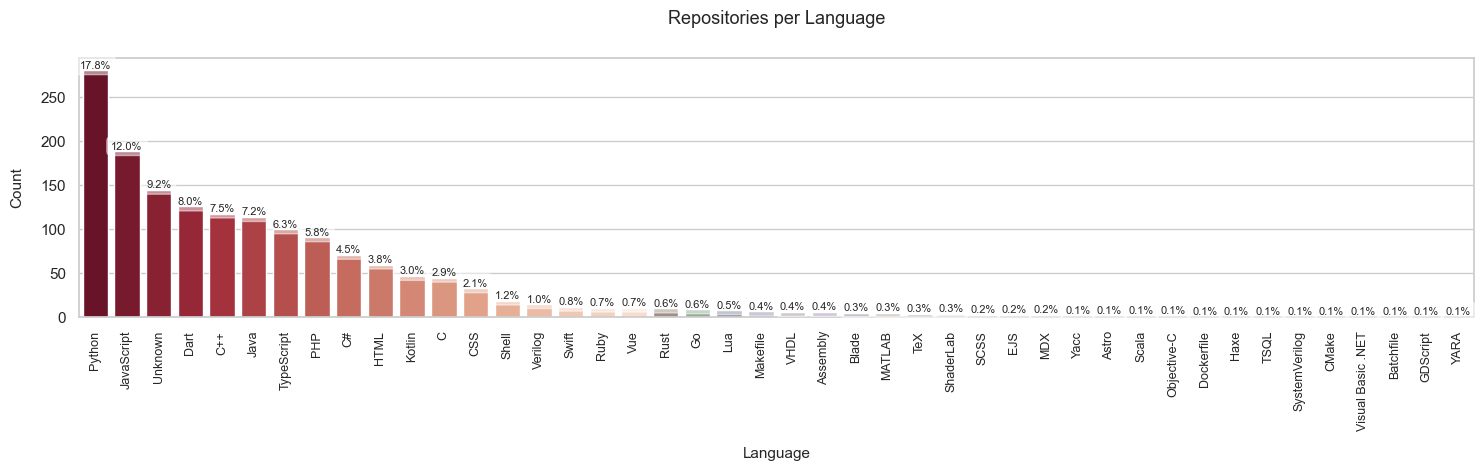

In [48]:
# Create a bar chart for language distribution
utils.plot_categories(df=language_counts, fontsize=11, save_name='Programming_Languages_Distribution')

### Observation

### Python is the most popular programming language among Egyptian GitHub developers, followed by JavaScript, while HTML, C#, PHP, TypeScript, Java, C++, and Dart are less commonly used.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>What are the most CI/CD Tools Used?</b>

In [49]:
ci__cd_tool = all_tools_melted.value_counts()
ci__cd_tool

value      
Docker         1300
Travis CI       986
Apache ANT      242
Azure           220
Codemagic       202
Argo CD         191
Unknown         173
AWS             162
DVC             159
CodeClimate      96
CircleCI         76
Name: count, dtype: int64

In [50]:
CICD__tool = pd.DataFrame(ci__cd_tool).reset_index()
CICD__tool

,value,count
0,Docker,1300
1,Travis CI,986
2,Apache ANT,242
3,Azure,220
4,Codemagic,202
5,Argo CD,191
6,Unknown,173
7,AWS,162
8,DVC,159
9,CodeClimate,96


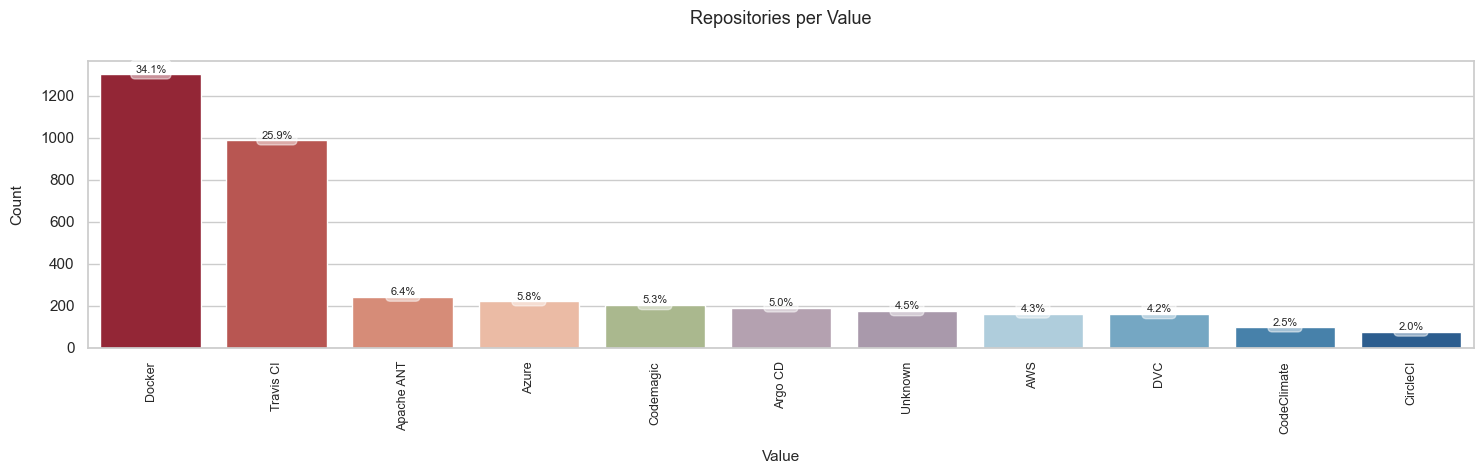

In [51]:
utils.plot_categories(df=CICD__tool, fontsize=11, save_name='CICD_Tools_Usage')

### Observation
### Docker, Travis CI is the most frequently used CI/CD tool among the top 11 tools used by developers, indicating its strong prevalence and importance in their workflows. While other tools like CircleCI, DVC, and CodeClimate are utilized, they appear less frequently compared to Docker, Travis CI.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Is there a relationship between Forks Count and Stargazers Count?</b>

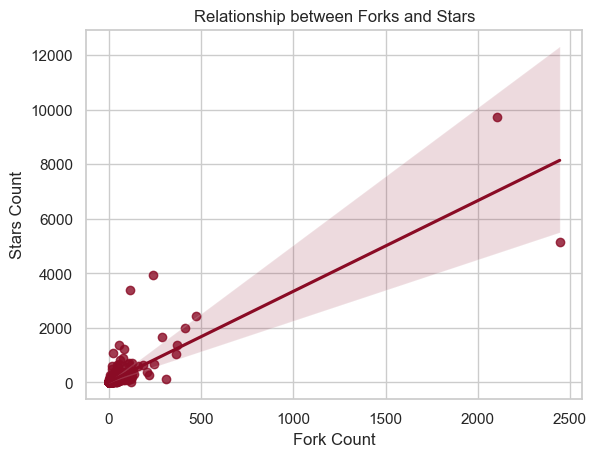

In [52]:
sns.regplot(data=df,x='forks_count',y='stargazers_count')
plt.title('Relationship between Forks and Stars')
plt.xlabel('Fork Count')
plt.ylabel('Stars Count')
save_and_show('Relationship_between_Forks_and_Stars')

### Observation
### There is a positive relationship between the number of forks and the number of stars. Repositories with more forks tend to have more stars. However, the relationship is not perfect, and there are likely other factors influencing the number of stars a repository receives.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Who are the top 10 active users?</b>

In [53]:
Most_Active_Users = df.sort_values(by=['public_repos','contribs_count'],ascending=False)
Most_Active_Users = Most_Active_Users.drop_duplicates(subset='name')
most_active_user = Most_Active_Users[['name','public_repos','contribs_count']].head(10)
most_active_user

,name,public_repos,contribs_count
1051,Abdelrazek,788,3
1052,Eslam Faisal,235,8
353,Amr Elsekilly,233,30
864,TomatoPHP,161,4
1146,Mohamed Tamer,157,9
417,Vardot,156,5
167,Ahmed Osama,153,2
1033,Khaled ElMorshedy,151,5
504,Cartologic,150,15
434,Maher El Gamil,141,5


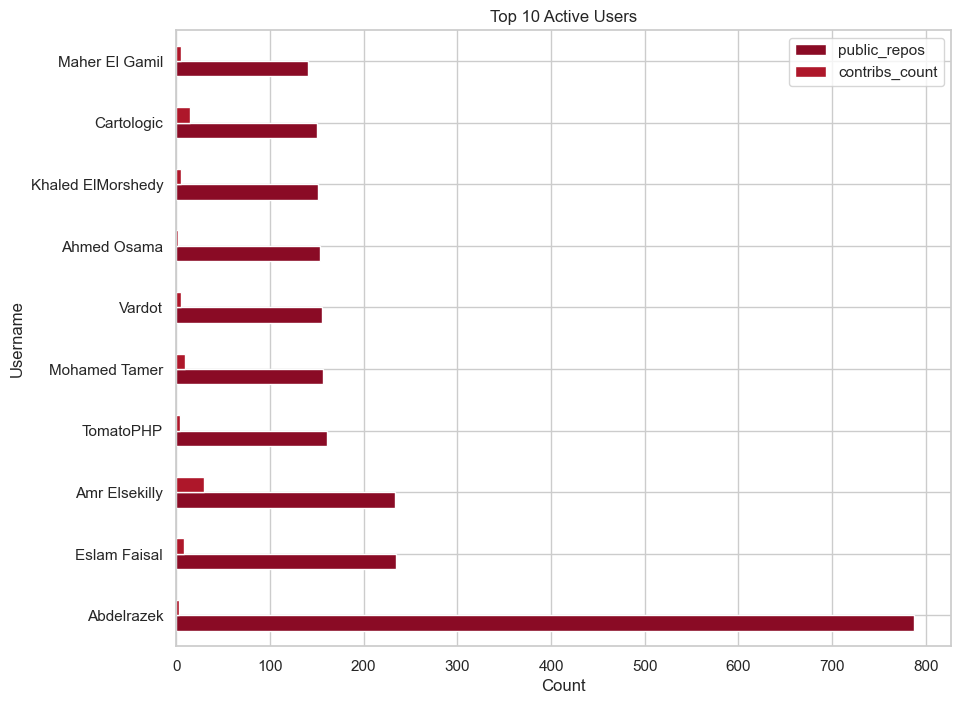

In [54]:
most_active_user.plot(kind='barh',x='name',y=['public_repos','contribs_count'],figsize=(10,8))
plt.title('Top 10 Active Users')
plt.xlabel('Count')
plt.ylabel('Username')
save_and_show('Top_10_Active_Users')

### Observation
### Abdelrazek has the highest number of public repositories, while Amr Elsekilly has the highest number of contributions among the listed users.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>What are the top 10 Popular Repos?</b>

In [55]:
Most_Popular_Repos = df.sort_values(by=['stargazers_count','forks_count'],ascending=False).head(10)
Most_Popular_Repos[['repo_name','stargazers_count','forks_count']]

,repo_name,stargazers_count,forks_count
467,sublist3r,9734,2104
571,deeplearning.ai-summary,5151,2444
372,autocomplete.js,3939,237
365,shell,3372,113
574,competitive-programming-li...,2445,472
650,cr3dov3r,2011,411
653,one-lin3r,1662,291
652,dr0p1t-framework,1379,372
1322,winpaletter,1360,56
1296,mybrain,1209,83


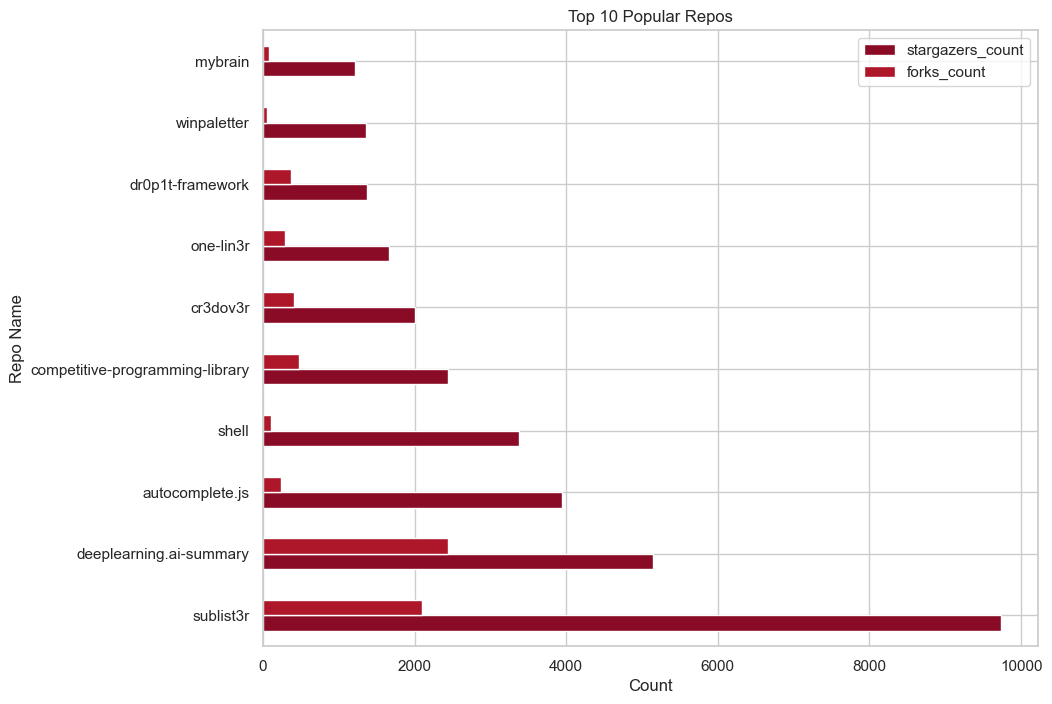

In [56]:
Most_Popular_Repos.plot(kind='barh',x='repo_name',y=['stargazers_count','forks_count'],figsize=(10,8))
plt.title('Top 10 Popular Repos')
plt.xlabel('Count')
plt.ylabel('Repo Name')
save_and_show('Top_10_Popular_Repos')

### Observation
### The "sublist3r" repository has the highest number of stars, while the "deeplearning.ai-summary" repository has the highest number of forks among the top 10 popular repositories listed.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Who has the most followers and the most following?</b>

In [57]:
Users_Follow = df.sort_values(by=['followers','following'],ascending=False)
Users_Follow = Users_Follow.drop_duplicates(subset='name')
User_follows = Users_Follow[['name','followers','following']].head(10)
User_follows

,name,followers,following
542,Mahmoud Ahmed,3198,264
344,Osama,2768,0
1060,Abdullah Mansour,2724,0
647,Karim shoair,1866,79
453,Ebrahem Hegazy,1843,2
466,Ahmed Aboul-Ela,1299,2
1336,Hesham Haroon,1166,6
571,Mahmoud Badry,1004,5
1146,Mohamed Tamer,989,428
1397,Kerollos Magdy,956,35


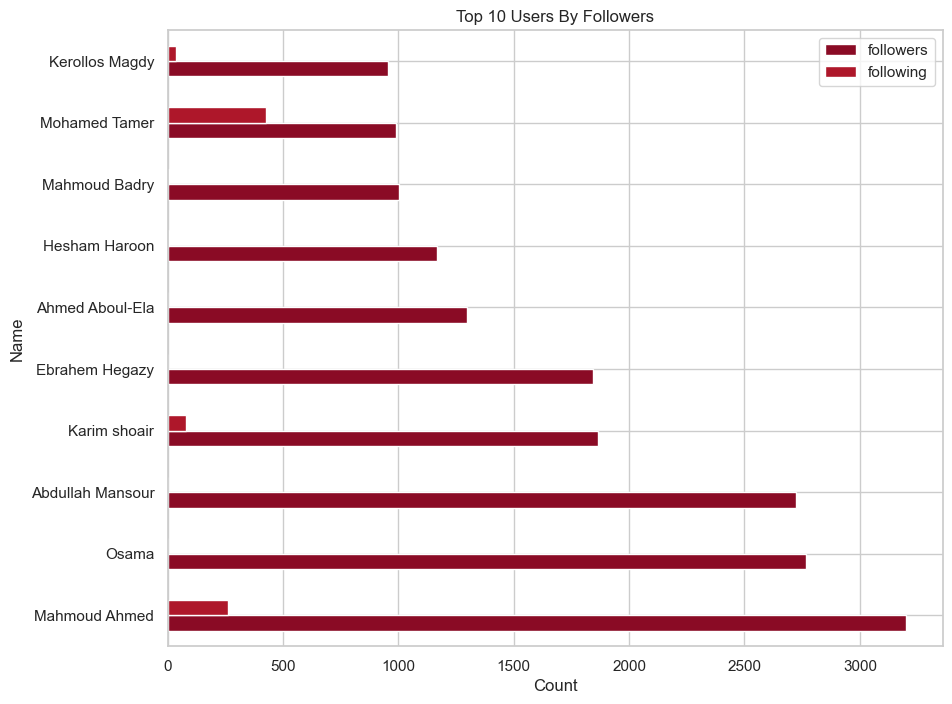

In [58]:
User_follows.plot(kind='barh',x='name',y=['followers','following'],figsize=(10,8))
plt.title('Top 10 Users By Followers')
plt.xlabel('Count')
plt.ylabel('Name')
save_and_show('Top_10_Users_By_Followers')

### Observation
### Mahmoud Ahmed has the highest number of followers among the listed users, significantly more than any other individual. While Mohamed Tamer also has the highest number of followings. The remaining users have comparatively low follower counts, and several have minimal or zero "following" counts.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Which cities have highest concentration of developers?</b>

In [59]:
# Group repositories by city and count occurrences
all_cities = pd.DataFrame(df[['location']].value_counts()).reset_index()
all_cities

,location,count
0,egypt,750
1,cairo,509
2,alexandria,128
3,giza,72
4,dakahlia,25
5,sharqia,14
6,north sinai,11
7,port said,11
8,gharbia,10
9,assiut,8


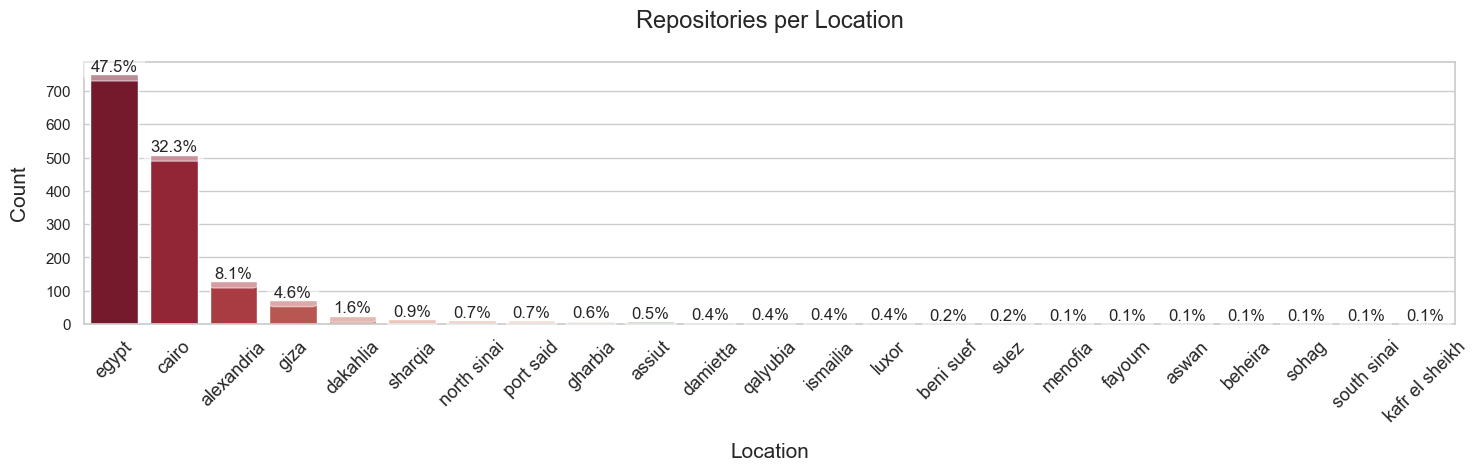

In [60]:
utils.plot_categories(all_cities, fontsize=15, figsize = (15, 5), rotation=45, save_name='Locations_Distribution')

### Observation
### Cairo and Egypt are the most frequently listed locations for users, suggesting a strong concentration of users identifying with these broader or capital-specific designations. Other specific cities like Alexandria, Giza, and Mansoura are represented, but with significantly lower counts. The presence of "Egypt" as a top location likely encompasses users who may not have specified a more granular city within the country.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>How the contributions of developers evolved over time?</b>

In [61]:
contribution_over_time = df.groupby(df['new_profile_created_at'].dt.year)['repo_name'].count()
contribution_over_times = pd.DataFrame(contribution_over_time)
contribution_over_times

,repo_name
new_profile_created_at,
2008,2
2009,5
2010,9
2011,19
2012,22
2013,47
2014,62
2015,103
2016,143


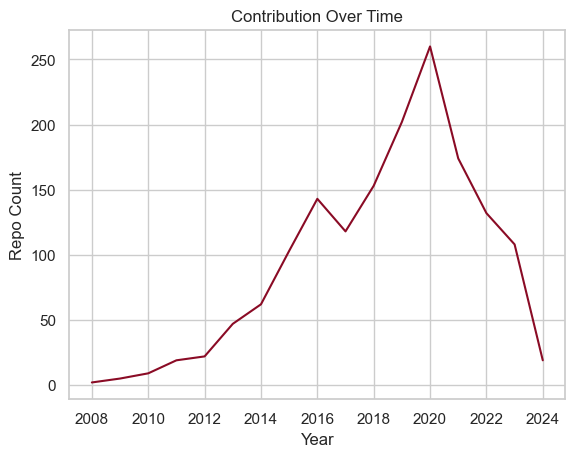

In [62]:
sns.lineplot(data=contribution_over_times,x=contribution_over_time.index,y=contribution_over_time.values)
plt.title('Contribution Over Time')
plt.xlabel('Year')
plt.ylabel('Repo Count')
save_and_show('Contribution_Over_Time')

### Observation
### There is a general upward trend in repository count over time, with a particularly significant surge around 2020, followed by a plateau and a slight decline towards 2024. This suggests a period of rapid growth in repository creation, followed by a stabilization or slight decrease in more recent years.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>What are the most licenses used?</b>

In [63]:
licenses = df['license'].value_counts().head(10)
licenses

license
Unknown                                   908
MIT License                               422
GNU General Public License v3.0            78
Apache License 2.0                         61
Other                                      45
GNU General Public License v2.0            14
GNU Affero General Public License v3.0     13
SIL Open Font License 1.1                   6
GNU Lesser General Public License v3.0      4
GNU Lesser General Public License v2.1      4
Name: count, dtype: int64

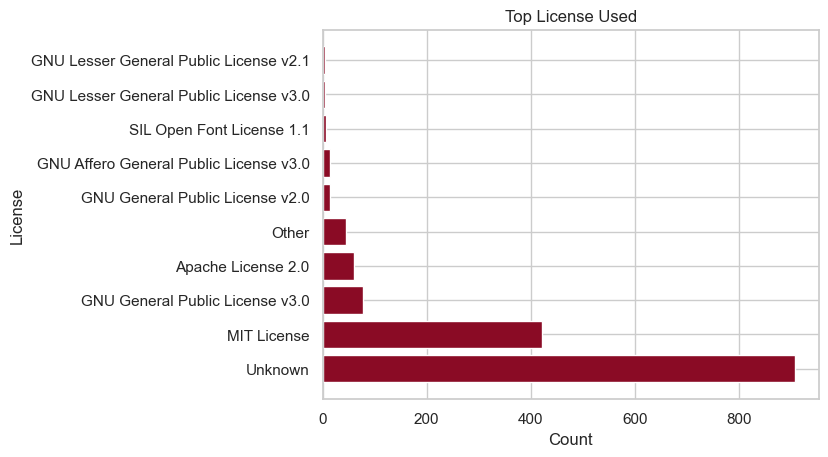

In [64]:
plt.barh(licenses.index,licenses.values)
plt.title('Top License Used')
plt.xlabel('Count')
plt.ylabel('License')
save_and_show('Top_License_Used')

### Observation
### The chart clearly illustrates the dominance of the MIT License as the most frequently used license, reflecting its widespread popularity in software projects. However, the substantial proportion of licenses categorized as 'Unknown' represent cases where licenses were not explicitly specified. Furthermore, the diversity of GNU and Apache licenses underscores the pervasive adoption of open-source software, highlighting the growing trend towards collaboration and shared software development. The presence of an 'Other' category indicates a variety of licenses that do not fall under the main categories, necessitating a separate study of these licenses to understand their nature and impact on projects.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>What are the Percentage of Open Issues and Closed Issues?</b>

In [65]:
open_issue_count = df[df['open_issues'] != -1]
open_issues_counts = open_issue_count[['open_issues']].sum()
open_issues_counts

open_issues    1485.0
dtype: float64

In [66]:
closed_issue_count = df[df['closed_issues'] != -1]
closed_issues_counts = closed_issue_count[['closed_issues']].sum()
closed_issues_counts

closed_issues    7012.0
dtype: float64

In [67]:
issues = [1485 , 7012]
Issues = pd.Series(issues,index=['Open_Issues','Closed_Issues'])
Issues

Open_Issues      1485
Closed_Issues    7012
dtype: int64

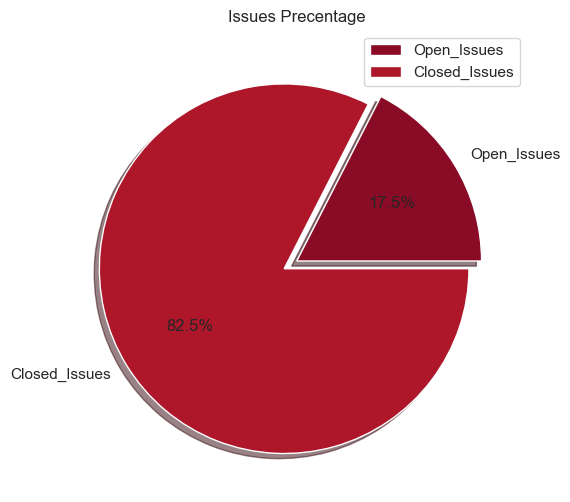

In [68]:
plt.figure(figsize=(8,6))
explode = (0,0.08)
plt.pie(Issues.values,labels=Issues.index,explode=explode,autopct='%1.1f%%',shadow=True)
plt.title('Issues Precentage')
plt.legend(Issues.index)
save_and_show('Issues_Percentage')

### Observation
### The pie chart clearly demonstrates a significant disparity between closed and open issues, with closed issues comprising the vast majority at 82.5%, while open issues account for only 17.5%. This indicates a high rate of issue resolution or closure within the dataset, suggesting effective management or a mature project state.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>What are the percentage of Open Pull Requests and Closed Pull Requests?</b>

In [69]:
open_pull_req_count = df[df['open_pull_requests'] != -1]
open_pull_req_counts = open_pull_req_count[['open_pull_requests']].sum()
open_pull_req_counts

open_pull_requests    658.0
dtype: float64

In [70]:
closed_pull_req_count = df[df['closed_pull_requests'] != -1]
closed_pull_req_counts = closed_pull_req_count[['closed_pull_requests']].sum()
closed_pull_req_counts

closed_pull_requests    5847.0
dtype: float64

In [71]:
pull_req = [685 , 5847]
Pull_Req = pd.Series(pull_req,index=['Open_Pull_Req','Closed_Pull_Req'])
Pull_Req

Open_Pull_Req       685
Closed_Pull_Req    5847
dtype: int64

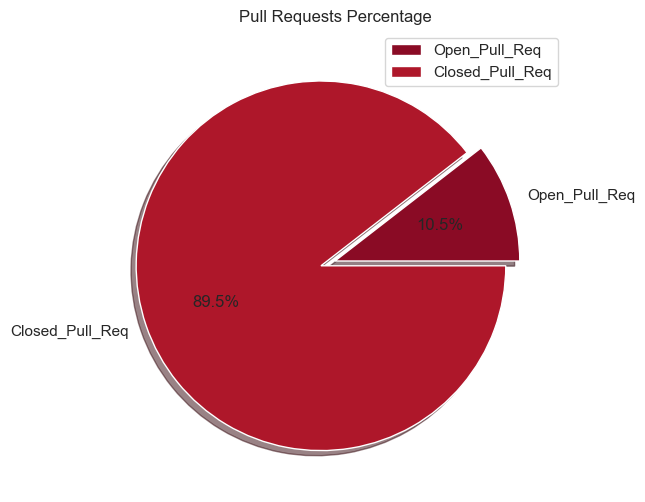

In [72]:
plt.figure(figsize=(8,6))
plt.pie(Pull_Req.values,labels=Pull_Req.index,shadow=True,autopct='%1.1f%%',explode=explode)
plt.legend(Pull_Req.index)
plt.title('Pull Requests Percentage')
save_and_show('Pull_Requests_Percentage')

### Observation
### The pie chart reveals a clear dominance of closed pull requests, accounting for 89.5% of the total, while open pull requests represent only 10.5%. This indicates a highly efficient process of reviewing and merging pull requests, suggesting a well-managed or mature project with a strong emphasis on code integration.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Frequency of documentation score</b>

In [73]:
doc_score_count = df['documentation_score'].value_counts()
doc_score_count

documentation_score
5    494
4    484
6    292
7    171
8     57
1     34
0     22
2     18
3      6
Name: count, dtype: int64

In [74]:
doc_score_count.index

Index([5, 4, 6, 7, 8, 1, 0, 2, 3], dtype='int64', name='documentation_score')

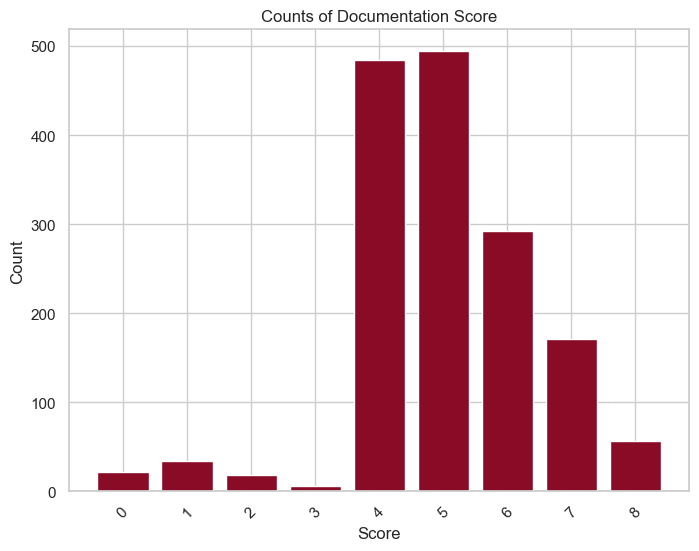

In [75]:
plt.figure(figsize=(8,6))
plt.bar(x=doc_score_count.index,height=doc_score_count.values)
plt.xticks(doc_score_count.index,labels=doc_score_count.index,rotation=45)
plt.title('Counts of Documentation Score')
plt.xlabel('Score')
plt.ylabel('Count')
save_and_show('Documentation_Scores')

### Observation
### The bar chart effectively visualizes the distribution of 'Documentation Scores'. There's a noticeable concentration of scores around 4, 5, and 6, indicating these are the most frequently assigned documentation scores. Conversely, scores 0, 1, 2, 3, 7, and 8 show significantly lower counts, suggesting these scores are less common within the dataset."

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:180%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:800;
            text-align:
            center;"><b>Statistical Analysis & Hypothesis Testing</b>

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Hypothesis Test 1: Relationship Between Repository Stars and Forks</b>

### Research Question
Is there a statistically significant association between the number of stars and forks received by Egyptian open-source repositories?

### Why Does This Matter?
Stars can indicate community interest in a repository, while forks reflect users copying a repository to explore, modify, or build upon its code. Understanding their relationship helps us investigate whether repositories that attract more attention also tend to attract more code reuse or experimentation.

### Hypotheses
- **Null Hypothesis (H₀):** There is no monotonic association between repository stars and forks in the population under study.
- **Alternative Hypothesis (H₁):** There is a monotonic association between repository stars and forks.

### Statistical Method
We use **Spearman's rank correlation** because it measures the strength and direction of a monotonic relationship without requiring the relationship to be linear.

We use a significance level of **α = 0.05**.

In [76]:
# Hypothesis Testing: Stars vs. Forks

# Prepare the variables
corr_data = df_analysis[
    ["stargazers_count", "forks_count"]
].copy()

corr_data = corr_data.replace([np.inf, -np.inf], np.nan).dropna()

# Spearman correlation
rho, p_value = spearmanr(
    corr_data["stargazers_count"],
    corr_data["forks_count"]
)

n = len(corr_data)

print("Hypothesis: Stars are associated with Forks")
print("-" * 45)
print(f"Sample size: {n}")
print(f"Spearman correlation (rho): {rho:.4f}")
print(f"P-value: {p_value:.6g}")

alpha = 0.05

if p_value < alpha:
    print(
        "\nDecision: Reject H0. "
        "There is statistically significant evidence of an association."
    )
else:
    print(
        "\nDecision: Fail to reject H0. "
        "There is insufficient evidence of an association."
    )


Hypothesis: Stars are associated with Forks
---------------------------------------------
Sample size: 1578
Spearman correlation (rho): 0.6643
P-value: 1.85567e-201

Decision: Reject H0. There is statistically significant evidence of an association.


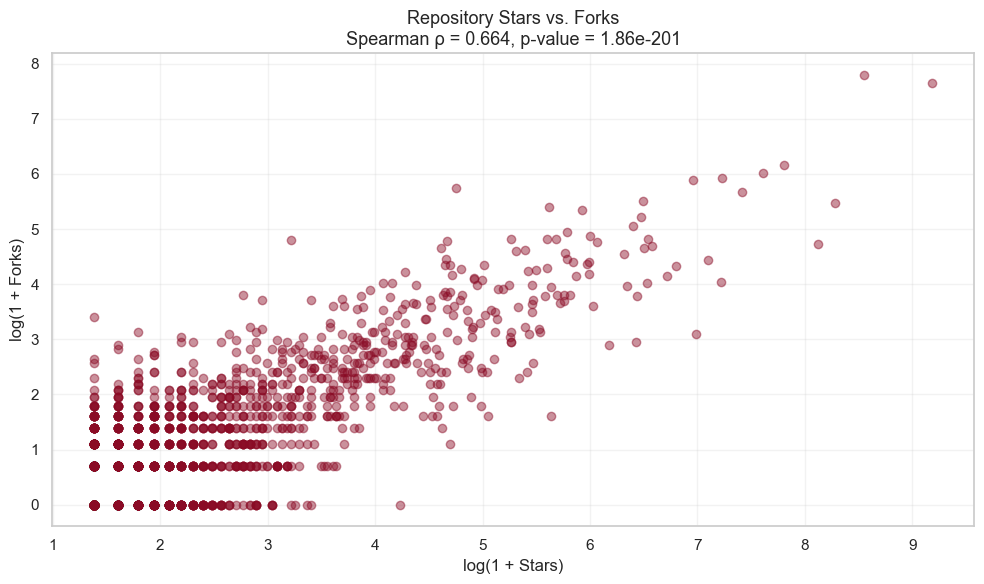

In [77]:
# Prepare data
plot_data = df_analysis[
    ["stargazers_count", "forks_count"]
].copy()

plot_data = plot_data.apply(
    lambda col: pd.to_numeric(col, errors="coerce")
)

plot_data = plot_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Calculate Spearman correlation
rho, p_value = spearmanr(
    plot_data["stargazers_count"],
    plot_data["forks_count"]
)

# Log transformation for visualization only
x = np.log1p(plot_data["stargazers_count"])
y = np.log1p(plot_data["forks_count"])

plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.45)

plt.title(
    f"Repository Stars vs. Forks\n"
    f"Spearman ρ = {rho:.3f}, p-value = {p_value:.2e}",
    fontsize=13
)
plt.xlabel("log(1 + Stars)")
plt.ylabel("log(1 + Forks)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
save_and_show('Forks_vs_Stars')


### Results
- Sample size: **1,578 repositories**
- Spearman's correlation coefficient (ρ): **0.6643**
- P-value: **1.85567 × 10⁻²⁰¹**
- Decision: **Reject H₀**

### Interpretation
The results indicate a statistically significant, positive monotonic association between stars and forks. Repositories with higher star counts tend, in general, to also have higher fork counts.

The correlation coefficient of 0.6643 indicates a substantial positive association in this dataset. The extremely small p-value provides strong evidence against the null hypothesis.

### Analytical Insight
Within this dataset, repository popularity measured by stars is strongly associated with community activity measured by forks. This suggests that repositories attracting more attention also tend to be forked more frequently.

**Important limitation:** Correlation does not establish causation. These results do not prove that receiving more stars causes a repository to receive more forks. Other factors, such as repository age, project type, and visibility, may influence both metrics.

### Conclusion
The analysis provides strong statistical evidence of a positive association between stars and forks among the 1,578 repositories analyzed. This finding motivates further investigation into other factors associated with repository popularity and community engagement.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Hypothesis Test 2: Contributors and Repository Popularity</b>

### Research Question
Is the number of contributors associated with repository popularity, measured by stars and forks, among Egyptian open-source repositories?

### Hypotheses
For each relationship:

- **H₀:** There is no monotonic association between the number of contributors and the popularity metric.
- **H₁:** There is a monotonic association between the number of contributors and the popularity metric.

### Statistical Method
Spearman's rank correlation was used to measure the direction and strength of monotonic relationships. The Benjamini–Hochberg procedure was applied to adjust p-values for the two hypothesis tests.

The significance level was set to α = 0.05.

In [78]:
tests = [
    ("Contributors vs Stars", "contribs_count", "stargazers_count"),
    ("Contributors vs Forks", "contribs_count", "forks_count")
]

results = []

for test_name, col_x, col_y in tests:
    temp = df_analysis[[col_x, col_y]].copy()

    for col in [col_x, col_y]:
        temp[col] = pd.to_numeric(temp[col], errors="coerce")

    temp = temp.replace([np.inf, -np.inf], np.nan).dropna()

    rho, p_value = spearmanr(temp[col_x], temp[col_y])

    results.append({
        "Hypothesis": test_name,
        "Sample_Size": len(temp),
        "Spearman_Rho": rho,
        "P_Value": p_value
    })

results_df = pd.DataFrame(results)

results_df["Adjusted_P_Value"] = multipletests(
    results_df["P_Value"],
    method="fdr_bh"
)[1]

results_df["Significant"] = (
    results_df["Adjusted_P_Value"] < 0.05
)

display(results_df.round(6))


,Hypothesis,Sample_Size,Spearman_Rho,P_Value,Adjusted_P_Value,Significant
0,Contributors vs Stars,1578,0.003935,0.875884,0.875884,False
1,Contributors vs Forks,1578,0.122171,0.000001,0.000002,True


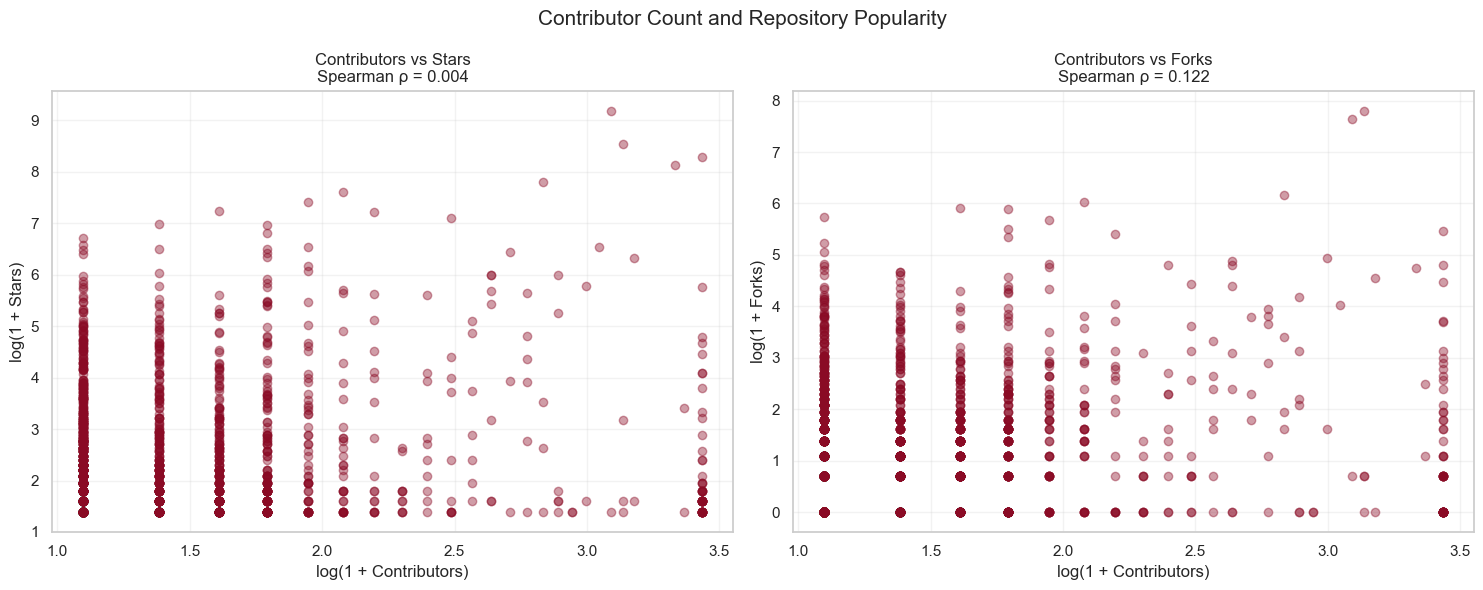

In [79]:
plot_data = df_analysis[
    ["contribs_count", "stargazers_count", "forks_count"]
].copy()

for col in plot_data.columns:
    plot_data[col] = pd.to_numeric(plot_data[col], errors="coerce")

plot_data = plot_data.replace([np.inf, -np.inf], np.nan).dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

relationships = [
    ("stargazers_count", "Stars", axes[0]),
    ("forks_count", "Forks", axes[1])
]

for target, label, ax in relationships:
    rho, p_value = spearmanr(
        plot_data["contribs_count"],
        plot_data[target]
    )

    ax.scatter(
        np.log1p(plot_data["contribs_count"]),
        np.log1p(plot_data[target]),
        alpha=0.4
    )

    ax.set_title(
        f"Contributors vs {label}\n"
        f"Spearman ρ = {rho:.3f}"
    )
    ax.set_xlabel("log(1 + Contributors)")
    ax.set_ylabel(f"log(1 + {label})")
    ax.grid(True, alpha=0.25)

plt.suptitle("Contributor Count and Repository Popularity", fontsize=15)
plt.tight_layout()
save_and_show('Contributors_vs_Repository_Popularity')

### Results

**1. Contributors vs. Stars**
- Sample size: 1,578 repositories
- Spearman's ρ: 0.003935
- Adjusted p-value: 0.875884
- Decision: Fail to reject H₀.

The results provide insufficient statistical evidence of a monotonic association between contributor count and star count. The observed correlation is effectively zero.

**2. Contributors vs. Forks**
- Sample size: 1,578 repositories
- Spearman's ρ: 0.122171
- Adjusted p-value: 0.000002
- Decision: Reject H₀.

The results indicate a statistically significant but weak positive monotonic association between contributor count and fork count. Repositories with more contributors tend to have somewhat higher fork counts, although the relationship is limited in strength.

### Analytical Insights
Contributor count does not appear to be a useful standalone indicator of star-based popularity in this dataset. Its relationship with forks is statistically significant, but the small correlation coefficient suggests limited predictive value on its own.

These findings highlight that popularity and community participation are not necessarily interchangeable concepts. Other factors, including repository age, project purpose, visibility, and development activity, may contribute to differences in stars and forks.

### Limitations
Correlation does not establish causation. Statistical significance does not imply a strong or practically important relationship. These findings describe the observed dataset and should not automatically be generalized to all Egyptian open-source projects.

### Conclusion
The analysis found no statistically significant association between contributor count and stars, but identified a weak, statistically significant positive association between contributor count and forks. This distinction provides a useful starting point for investigating the different dimensions of repository popularity and community engagement.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Hypothesis Test 3: Documentation Score and Repository Popularity</b>

### Research Question
Is the repository documentation heuristic score associated with repository popularity, measured by stars and forks?

### Understanding the Documentation Score
The `documentation_score` ranges from 0 to 8 and measures the presence of predefined documentation-related indicators. It is not a direct assessment of documentation quality, clarity, completeness, or usefulness.

### Hypotheses
Two relationships were examined:

**Test A: Documentation Score vs. Stars**
- H₀: There is no monotonic association between documentation score and star count.
- H₁: There is a monotonic association between documentation score and star count.

**Test B: Documentation Score vs. Forks**
- H₀: There is no monotonic association between documentation score and fork count.
- H₁: There is a monotonic association between documentation score and fork count.

### Statistical Method
Spearman's rank correlation was used to evaluate the direction and strength of monotonic associations. The Benjamini–Hochberg procedure was used to adjust p-values across the two tests, with a significance threshold of α = 0.05.

In [80]:
tests = [
    ("Documentation Score vs Stars",
     "documentation_score", "stargazers_count"),

    ("Documentation Score vs Forks",
     "documentation_score", "forks_count")
]

results = []

for test_name, score_col, popularity_col in tests:
    temp = df_analysis[[score_col, popularity_col]].copy()

    for col in [score_col, popularity_col]:
        temp[col] = pd.to_numeric(temp[col], errors="coerce")

    temp = temp.replace([np.inf, -np.inf], np.nan).dropna()

    # Exclude invalid documentation scores, if any
    temp = temp[temp[score_col].between(0, 8)]

    rho, p_value = spearmanr(
        temp[score_col],
        temp[popularity_col]
    )

    results.append({
        "Hypothesis": test_name,
        "Sample_Size": len(temp),
        "Spearman_Rho": rho,
        "P_Value": p_value
    })

results_df = pd.DataFrame(results)

results_df["Adjusted_P_Value"] = multipletests(
    results_df["P_Value"],
    method="fdr_bh"
)[1]

results_df["Significant"] = (
    results_df["Adjusted_P_Value"] < 0.05
)


display(results_df.round(6))

,Hypothesis,Sample_Size,Spearman_Rho,P_Value,Adjusted_P_Value,Significant
0,Documentation Score vs Stars,1578,-0.146166,0.000000,0.000000,True
1,Documentation Score vs Forks,1578,-0.024808,0.324705,0.324705,False


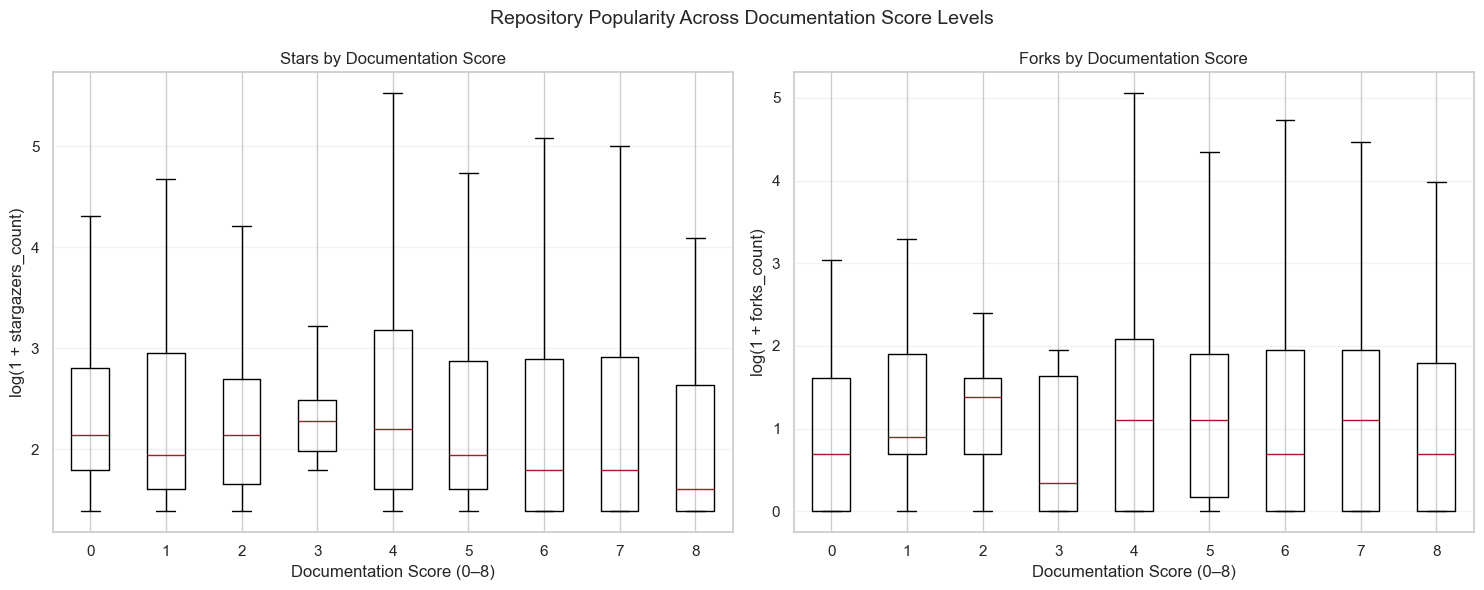

In [81]:
plot_data = df_analysis[
    ["documentation_score", "stargazers_count", "forks_count"]
].copy()

for col in plot_data.columns:
    plot_data[col] = pd.to_numeric(plot_data[col], errors="coerce")

plot_data = plot_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

plot_data = plot_data[
    plot_data["documentation_score"].between(0, 8)
].copy()

plot_data["documentation_score"] = (
    plot_data["documentation_score"].astype(int)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, metric, title in [
    (axes[0], "stargazers_count", "Stars by Documentation Score"),
    (axes[1], "forks_count", "Forks by Documentation Score")
]:
    scores = sorted(plot_data["documentation_score"].unique())

    groups = [
        np.log1p(
            plot_data.loc[
                plot_data["documentation_score"] == score, metric
            ].clip(lower=0)
        )
        for score in scores
    ]

    ax.boxplot(groups, tick_labels=scores, showfliers=False)
    ax.set_title(title)
    ax.set_xlabel("Documentation Score (0–8)")
    ax.set_ylabel(f"log(1 + {metric})")
    ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "Repository Popularity Across Documentation Score Levels",
    fontsize=14
)
plt.tight_layout()
save_and_show('Repository_Popularity_by_Documentation_Score')

### Results

**1. Documentation Score vs. Stars**
- Sample size: 1,578 repositories
- Spearman's ρ: -0.146166
- Adjusted p-value: reported as 0.000000 after rounding
- Decision: Reject H₀.

The analysis identifies a statistically significant but weak negative monotonic association between documentation score and star count. In this dataset, repositories with higher heuristic scores tend to have lower star counts, although the association is weak.

**2. Documentation Score vs. Forks**
- Sample size: 1,578 repositories
- Spearman's ρ: -0.024808
- Adjusted p-value: 0.324705
- Decision: Fail to reject H₀.

The observed correlation is close to zero, and the test does not provide sufficient evidence of a monotonic association between documentation score and fork count.

### Analytical Insights
The results suggest that the documentation heuristic score behaves differently across the two popularity measures. It has a weak negative association with stars, while no statistically significant monotonic association was detected with forks.

These findings do not imply that better documentation reduces popularity. The score measures the presence of predefined elements rather than actual documentation quality. Repository type, age, visibility, project purpose, and the scoring rules themselves may contribute to the observed relationship.

### Limitations
The results describe associations in the analyzed dataset and do not establish causation. A non-significant result does not prove that no relationship exists. In addition, the heuristic score should not be treated as a direct measure of documentation quality.

### Conclusion
The analysis found a weak, statistically significant negative association between documentation score and stars, but no statistically significant monotonic association between documentation score and forks. Further analysis is needed to investigate whether repository characteristics explain these patterns.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:130%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:400"><b>Hypothesis Test 4: Programming Language and Repository Popularity</b>

### Research Question
Do repository star and fork count distributions differ across programming-language groups?

### Statistical Method
The Kruskal–Wallis H-test was applied to compare repository popularity across language groups containing at least 30 repositories. P-values were adjusted using the Benjamini–Hochberg procedure across the two tests, with a significance level of α = 0.05.

In [82]:
language_data = df_analysis[
    ["language", "stargazers_count", "forks_count"]
].copy()

# Standardize language labels and numeric columns
language_data["language"] = (
    language_data["language"]
    .astype("string")
    .str.strip()
)

for col in ["stargazers_count", "forks_count"]:
    language_data[col] = pd.to_numeric(
        language_data[col], errors="coerce"
    )

language_data = language_data.replace(
    [np.inf, -np.inf], np.nan
)

# Exclude missing and empty language labels
language_data = language_data[
    language_data["language"].notna()
    & language_data["language"].ne("")
].copy()

language_counts = (
    language_data.groupby("language")
    .size()
    .sort_values(ascending=False)
    .rename("Repository_Count")
    .reset_index()
)

display(language_counts.head(20))

,language,Repository_Count
0,Python,281
1,JavaScript,189
2,Unknown,145
3,Dart,126
4,C++,118
5,Java,114
6,TypeScript,100
7,PHP,91
8,C#,71
9,HTML,60


In [83]:
MIN_REPOS_PER_LANGUAGE = 30

eligible_languages = language_counts.loc[
    language_counts["Repository_Count"]
    >= MIN_REPOS_PER_LANGUAGE,
    "language"
].tolist()

print("Number of eligible languages:", len(eligible_languages))
print("Eligible languages:", eligible_languages)

if len(eligible_languages) < 2:
    print(
        "Not enough eligible language groups for "
        "a Kruskal-Wallis comparison. Consider reviewing "
        "the minimum group-size threshold."
    )
else:
    test_data = language_data[
        language_data["language"].isin(eligible_languages)
    ].copy()

    results = []

    for metric in ["stargazers_count", "forks_count"]:
        groups = [
            group[metric].dropna().to_numpy()
            for _, group in test_data.groupby("language")
        ]

        # Retain groups with observations for this metric
        groups = [g for g in groups if len(g) > 0]

        if len(groups) >= 2:
            h_stat, p_value = kruskal(*groups)

            results.append({
                "Metric": metric,
                "Number_of_Groups": len(groups),
                "Total_Sample_Size": sum(len(g) for g in groups),
                "Kruskal_H": h_stat,
                "P_Value": p_value
            })

    results_df = pd.DataFrame(results)

    if not results_df.empty:
        results_df["Adjusted_P_Value"] = multipletests(
            results_df["P_Value"],
            method="fdr_bh"
        )[1]

        results_df["Significant"] = (
            results_df["Adjusted_P_Value"] < 0.05
        )

        display(
            results_df.style.format({
                "Kruskal_H": "{:.4f}",
                "P_Value": "{:.3e}",
                "Adjusted_P_Value": "{:.3e}"
            })
        )

Number of eligible languages: 13
Eligible languages: ['Python', 'JavaScript', 'Unknown', 'Dart', 'C++', 'Java', 'TypeScript', 'PHP', 'C#', 'HTML', 'Kotlin', 'C', 'CSS']


,Metric,Number_of_Groups,Total_Sample_Size,Kruskal_H,P_Value,Adjusted_P_Value,Significant
0,stargazers_count,13,1420,26.9836,7.769e-03,7.769e-03,True
1,forks_count,13,1420,43.4328,1.907e-05,3.814e-05,True


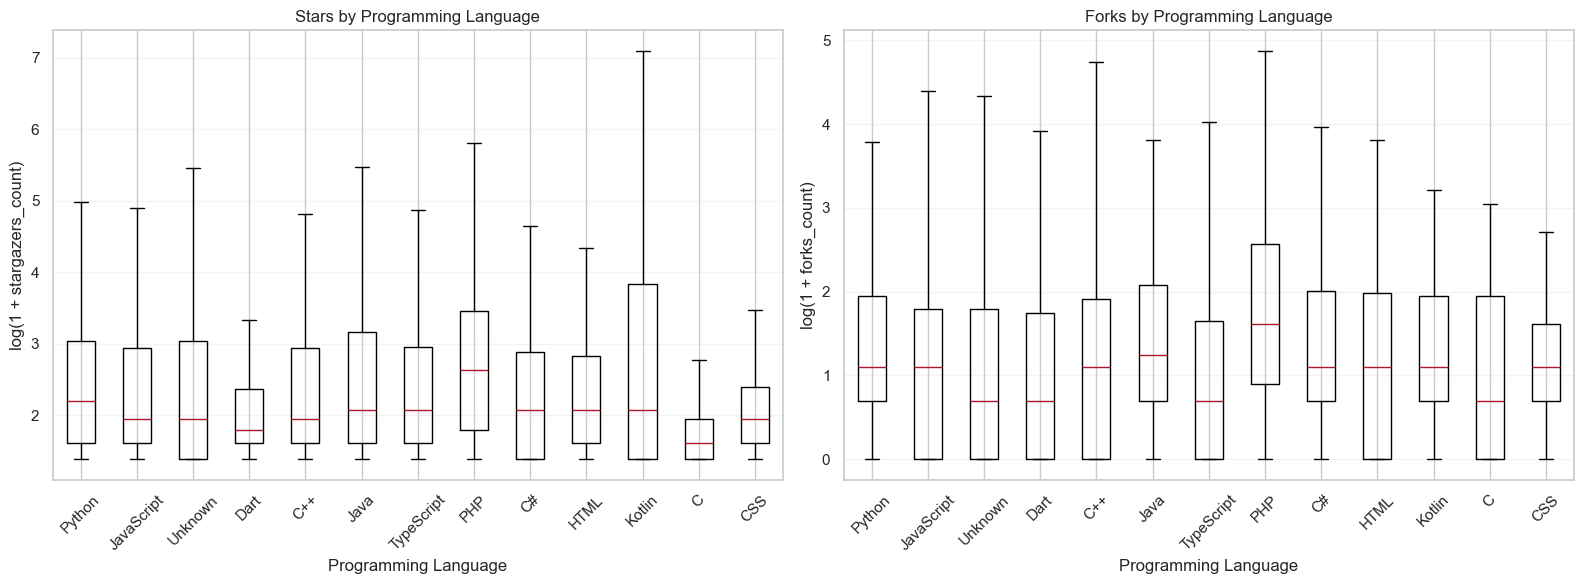

In [84]:
if len(eligible_languages) >= 2:
    plot_data = language_data[
        language_data["language"].isin(eligible_languages)
    ].copy()

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for ax, metric, title in [
        (axes[0], "stargazers_count", "Stars by Programming Language"),
        (axes[1], "forks_count", "Forks by Programming Language")
    ]:
        groups = []
        labels = []

        for lang in eligible_languages:
            values = plot_data.loc[
                plot_data["language"] == lang, metric
            ].dropna()

            if len(values) > 0:
                groups.append(np.log1p(values.clip(lower=0)))
                labels.append(lang)

        ax.boxplot(
            groups,
            tick_labels=labels,
            showfliers=False
        )
        ax.set_title(title)
        ax.set_xlabel("Programming Language")
        ax.set_ylabel(f"log(1 + {metric})")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    save_and_show('Repository_Popularity_by_Programming_Language')

### Results

**Stars**
- Number of groups: 13
- Total observations: 1,420
- Kruskal–Wallis H-statistic: 26.9836
- Adjusted p-value: 0.007769
- Decision: Reject H₀.

There is statistically significant evidence that star-count distributions differ across at least some of the selected language groups.

**Forks**
- Number of groups: 13
- Total observations: 1,420
- Kruskal–Wallis H-statistic: 43.4328
- Adjusted p-value: 0.00003814
- Decision: Reject H₀.

There is statistically significant evidence that fork-count distributions differ across at least some of the selected language groups.

### Analytical Interpretation
Programming-language groups exhibit statistically detectable differences in repository popularity within this dataset. However, the omnibus Kruskal–Wallis test does not identify which specific pairs of languages differ or establish a popularity ranking.

The `Unknown` language category was included in the initial analysis. Since it does not represent an actual programming language, a sensitivity analysis excluding this category is needed before drawing conclusions specifically about programming languages.

### Limitations
These findings indicate differences in distributions, not causation. Repository age, project type, visibility, and the number of repositories per language may influence the observed patterns. Post-hoc comparisons are required to identify specific group differences.

In [85]:
MIN_REPOS_PER_LANGUAGE = 30

# Exclude Unknown from the primary programming-language analysis
known_data = language_data[
    language_data["language"].notna()
    & language_data["language"].str.strip().ne("")
    & language_data["language"].str.casefold().ne("unknown")
].copy()

# Retain languages with at least 30 repositories
known_counts = known_data["language"].value_counts()
known_languages = sorted(
    known_counts[known_counts >= MIN_REPOS_PER_LANGUAGE].index
)

print("Number of known languages:", len(known_languages))
print("Languages:", known_languages)

posthoc_results = []

for metric in ["stargazers_count", "forks_count"]:
    for lang_a, lang_b in combinations(known_languages, 2):
        values_a = known_data.loc[
            known_data["language"] == lang_a, metric
        ].dropna().to_numpy()

        values_b = known_data.loc[
            known_data["language"] == lang_b, metric
        ].dropna().to_numpy()

        if len(values_a) == 0 or len(values_b) == 0:
            continue

        statistic, p_value = mannwhitneyu(
            values_a,
            values_b,
            alternative="two-sided"
        )

        posthoc_results.append({
            "Metric": metric,
            "Language_A": lang_a,
            "Language_B": lang_b,
            "N_A": len(values_a),
            "N_B": len(values_b),
            "Median_A": np.median(values_a),
            "Median_B": np.median(values_b),
            "P_Value": p_value
        })

posthoc_df = pd.DataFrame(posthoc_results)

# Adjust pairwise p-values separately for Stars and Forks
posthoc_df["Adjusted_P_Value"] = np.nan

for metric in posthoc_df["Metric"].unique():
    mask = posthoc_df["Metric"] == metric

    posthoc_df.loc[mask, "Adjusted_P_Value"] = multipletests(
        posthoc_df.loc[mask, "P_Value"],
        method="holm"
    )[1]

posthoc_df["Significant"] = (
    posthoc_df["Adjusted_P_Value"] < 0.05
)

posthoc_df = posthoc_df.sort_values(
    ["Metric", "Adjusted_P_Value"]
).reset_index(drop=True)

display(
    posthoc_df.style.format({
        "Median_A": "{:.1f}",
        "Median_B": "{:.1f}",
        "P_Value": "{:.3e}",
        "Adjusted_P_Value": "{:.3e}"
    })
)

Number of known languages: 12
Languages: ['C', 'C#', 'C++', 'CSS', 'Dart', 'HTML', 'Java', 'JavaScript', 'Kotlin', 'PHP', 'Python', 'TypeScript']


,Metric,Language_A,Language_B,N_A,N_B,Median_A,Median_B,P_Value,Adjusted_P_Value,Significant
0,forks_count,Dart,PHP,126,91,1.0,4.0,8.454e-07,5.580e-05,True
1,forks_count,JavaScript,PHP,189,91,2.0,4.0,2.667e-05,1.733e-03,True
2,forks_count,PHP,TypeScript,91,100,4.0,1.0,2.735e-05,1.750e-03,True
3,forks_count,C++,PHP,118,91,2.0,4.0,3.112e-04,1.960e-02,True
4,forks_count,Dart,Python,126,281,1.0,2.0,4.095e-04,2.539e-02,True
5,forks_count,C,PHP,45,91,1.0,4.0,2.229e-03,1.359e-01,False
6,forks_count,PHP,Python,91,281,4.0,2.0,3.557e-03,2.134e-01,False
7,forks_count,Dart,Java,126,114,1.0,2.5,4.076e-03,2.405e-01,False
8,forks_count,HTML,PHP,60,91,2.0,4.0,6.226e-03,3.611e-01,False
9,forks_count,CSS,PHP,33,91,2.0,4.0,7.160e-03,4.081e-01,False


## Post-hoc Analysis: Pairwise Differences Across Programming Languages

### Objective
Following the significant Kruskal–Wallis results, pairwise Mann–Whitney U tests were conducted to investigate which programming-language groups differed in repository popularity. Holm's procedure was used to adjust p-values for multiple pairwise comparisons separately for stars and forks.

### Significant Differences in Fork Counts
The reported results identified five statistically significant pairwise differences:

- **Dart vs. PHP:** median forks of 1 vs. 4.
- **JavaScript vs. PHP:** median forks of 2 vs. 4.
- **PHP vs. TypeScript:** median forks of 4 vs. 1.
- **C++ vs. PHP:** median forks of 2 vs. 4.
- **Dart vs. Python:** median forks of 1 vs. 2.

These comparisons suggest that PHP repositories have higher median fork counts than Dart, JavaScript, TypeScript, and C++ repositories in the observed sample. Python repositories also have a higher median fork count than Dart repositories in the reported comparison.

### Significant Differences in Star Counts
Two statistically significant pairwise differences were reported:

- **Dart vs. PHP:** median stars of 5 vs. 13.
- **C vs. PHP:** median stars of 4 vs. 13.

These results indicate higher median star counts for PHP repositories than for Dart and C repositories in the observed sample.

### Interpretation
The pairwise findings suggest that programming-language groups do not all exhibit the same popularity distributions. However, the detected differences apply only to the specific language pairs identified by the corrected tests.

Higher median popularity does not establish that a programming language causes repositories to attract more stars or forks. Repository age, project purpose, visibility, and other characteristics may explain some of the observed differences.

### Important Consistency Check
The initial Kruskal–Wallis analysis included the `Unknown` language category, whereas the pairwise analysis excluded it. The omnibus tests should be rerun using the same known-language groups as the pairwise analysis before the findings are finalized. This ensures that the overall and pairwise conclusions refer to a consistent set of groups.

In [86]:
known_data = language_data[
    language_data["language"].notna()
    & language_data["language"].str.strip().ne("")
    & language_data["language"].str.casefold().ne("unknown")
].copy()

MIN_REPOS_PER_LANGUAGE = 30

known_counts = known_data["language"].value_counts()

known_languages = sorted(
    known_counts[
        known_counts >= MIN_REPOS_PER_LANGUAGE
    ].index
)

sensitivity_results = []

for metric in ["stargazers_count", "forks_count"]:
    groups = []

    for lang in known_languages:
        values = known_data.loc[
            known_data["language"] == lang, metric
        ].dropna().to_numpy()

        if len(values) > 0:
            groups.append(values)

    if len(groups) >= 2:
        h_stat, p_value = kruskal(*groups)

        sensitivity_results.append({
            "Metric": metric,
            "Number_of_Groups": len(groups),
            "Total_Sample_Size": sum(len(g) for g in groups),
            "Kruskal_H": h_stat,
            "P_Value": p_value
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

sensitivity_df["Adjusted_P_Value"] = multipletests(
    sensitivity_df["P_Value"],
    method="fdr_bh"
)[1]

sensitivity_df["Significant"] = (
    sensitivity_df["Adjusted_P_Value"] < 0.05
)

display(
    sensitivity_df.style.format({
        "Kruskal_H": "{:.4f}",
        "P_Value": "{:.3e}",
        "Adjusted_P_Value": "{:.3e}"
    })
)

,Metric,Number_of_Groups,Total_Sample_Size,Kruskal_H,P_Value,Adjusted_P_Value,Significant
0,stargazers_count,12,1275,27.4318,3.953e-03,3.953e-03,True
1,forks_count,12,1275,38.3055,6.947e-05,1.389e-04,True


### Sensitivity Analysis: Programming Language vs Repository Popularity

To assess the robustness of the programming-language comparison, the Kruskal–Wallis tests were repeated after excluding repositories with an `Unknown` programming language. The analysis included 12 programming-language groups and 1,275 repositories.

The results remained statistically significant for both popularity metrics:

- **Stars:** H = 27.4318, adjusted p-value = 0.003953.
- **Forks:** H = 38.3055, adjusted p-value = 0.0001389.

Both adjusted p-values are below the significance threshold of 0.05. Therefore, the analysis provides evidence that repository popularity distributions differ across at least some programming-language groups, even when repositories with unknown languages are excluded.

These findings support the robustness of the omnibus results. However, Kruskal–Wallis does not identify which specific language pairs differ, and the results do not establish a causal relationship between programming language and popularity. Pairwise post-hoc comparisons are needed to investigate specific differences.

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:180%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:800;
            text-align:
            center;"><b>Repository Segmentation Using Clustering</b>

## 1. Objective

In this section, we will use **unsupervised machine learning** to segment Egyptian open-source repositories into groups with similar characteristics.

The goal is to move beyond descriptive analysis and identify meaningful repository segments based on their popularity and available documentation indicators.

This analysis will help us investigate questions such as:

- Can Egyptian open-source repositories be grouped into distinct segments based on their popularity?
- Do some repositories attract substantially more stars and forks than others?
- Do repository segments differ in their contributor counts or documentation indicators?
- What characteristics distinguish each identified segment?

## 2. Analytical Approach

We will follow a structured clustering workflow:

1. **Prepare the clustering dataset:** Select the relevant repository-level features and inspect their data types and missing values.
2. **Handle data limitations:** Investigate potentially unreliable variables and exclude features that could introduce misleading patterns.
3. **Engineer features:** Apply suitable transformations to highly skewed numerical variables.
4. **Scale numerical features:** Standardize the selected features so that differences in measurement scales do not dominate the clustering process.
5. **Determine the number of clusters:** Evaluate multiple values of K using the Elbow Method and Silhouette Score.
6. **Build the clustering model:** Apply K-Means using the selected features and number of clusters.
7. **Profile the resulting segments:** Compare cluster sizes, median values, and other repository characteristics.
8. **Visualize and interpret the results:** Examine whether the identified segments show meaningful differences in repository popularity.

## 3. Methodological Considerations

The clustering process will focus on repository-level numerical indicators, including stars, forks, and the documentation score, where appropriate.

Before finalizing the feature set, we will assess the reliability and completeness of each variable. Features with substantial missingness or potential data collection limitations will be treated cautiously.

Because repository popularity metrics are often highly skewed, transformations such as `log1p` may be applied before standardization.

We will also evaluate the stability and interpretability of the clustering results rather than relying exclusively on a single evaluation metric.

**Important:** Clustering identifies patterns of similarity; it does not establish causal relationships or guarantee that the resulting segments represent objectively defined categories of repository quality or success.

## 4. Data Preparation and Feature Selection

We will create a dedicated dataset for clustering while preserving the original analytical dataset.

The initial candidate features include:

- `stargazers_count`: Number of GitHub stars, used as a popularity indicator.
- `forks_count`: Number of repository forks, reflecting another aspect of repository engagement.
- `contribs_count`: Number of contributors, subject to a reliability assessment.
- `documentation_score`: A heuristic indicator of the presence of selected documentation elements.

We will also examine `last_repo_commit_date` to investigate repository activity. However, this variable has substantial missingness, so it will not automatically be included in the clustering model.

The final feature set will be determined after reviewing data quality, completeness, and potential collection limitations.

**Expected outcome:** A prepared dataset containing the repository identifiers, candidate clustering features, and any derived variables needed for subsequent analysis.

In [87]:
# Core features for repository segmentation
cluster_source = df_analysis[
    [
        "repo_name",
        "stargazers_count",
        "forks_count",
        "contribs_count",
        "documentation_score",
        "last_repo_commit_date",
        "language"
    ]
].copy()

# Convert numeric features safely
numeric_features = [
    "stargazers_count",
    "forks_count",
    "contribs_count",
    "documentation_score"
]

for col in numeric_features:
    cluster_source[col] = pd.to_numeric(
        cluster_source[col], errors="coerce"
    )

# Derive recency of the last repository commit
cluster_source["last_repo_commit_date"] = pd.to_datetime(
    cluster_source["last_repo_commit_date"],
    errors="coerce",
    utc=True
)

reference_date = pd.Timestamp.now(tz="UTC")

cluster_source["days_since_last_commit"] = (
    reference_date - cluster_source["last_repo_commit_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Inspect data quality
feature_cols = numeric_features + ["days_since_last_commit"]

quality_report = pd.DataFrame({
    "Data_Type": cluster_source[feature_cols].dtypes.astype(str),
    "Missing_Count": cluster_source[feature_cols].isna().sum(),
    "Missing_Percentage": (
        cluster_source[feature_cols].isna().mean() * 100
    ).round(2),
    "Negative_Count": (
        cluster_source[feature_cols].lt(0).sum()
    )
})

display(quality_report)

# Descriptive statistics
display(cluster_source[feature_cols].describe().T)

# Inspect extreme values and date conversion
print("Dataset shape:", cluster_source.shape)
print(
    "Invalid / missing last commit dates:",
    cluster_source["last_repo_commit_date"].isna().sum()
)
print(
    "Future last commit dates:",
    cluster_source["days_since_last_commit"].lt(0).sum()
)

,Data_Type,Missing_Count,Missing_Percentage,Negative_Count
stargazers_count,int64,0,0.0,0
forks_count,int64,0,0.0,0
contribs_count,int64,0,0.0,0
documentation_score,int64,0,0.0,0
days_since_last_commit,float64,1234,78.2,0


,count,mean,std,min,25%,50%,75%,max
stargazers_count,1578.0,52.259189,333.819138,3.000000,4.000000,7.000000,19.000000,9734.000000
forks_count,1578.0,12.200253,86.393184,0.000000,0.000000,2.000000,6.000000,2444.000000
contribs_count,1578.0,4.591255,5.675619,2.000000,2.000000,3.000000,4.000000,30.000000
documentation_score,1578.0,5.005703,1.436226,0.000000,4.000000,5.000000,6.000000,8.000000
days_since_last_commit,344.0,895.332389,106.897346,752.097641,792.016394,886.206328,982.057447,1113.318093


Dataset shape: (1578, 8)
Invalid / missing last commit dates: 1234
Future last commit dates: 0


### Data Preparation Review

The candidate features have been prepared for further analysis, including the conversion of numerical columns to appropriate numeric types and the derivation of repository recency where possible.

The completeness of each feature must be considered before using it in clustering. In particular, a variable with a large proportion of missing values may introduce bias or substantially reduce the number of usable repositories.

For this analysis, `last_repo_commit_date` has approximately **78.2% missing values**. Therefore, the derived recency feature will be excluded from the current clustering model.

We will also investigate whether `contribs_count` may contain collection-related limitations before deciding whether it should remain in the final feature set.

---------------------------------------------------------------------

## 5. Feature Transformation and Scaling

Repository popularity variables such as stars and forks typically have highly skewed distributions: many repositories have relatively low counts, while a small number attract substantially more attention.

To reduce the influence of extreme values, we will apply the `log1p` transformation to stars and forks:

\[
x_{\text{transformed}} = \log(1+x)
\]

The transformation reduces skewness while preserving zero values.

Next, we will standardize the selected features using `StandardScaler`. This places the features on a comparable scale, which is important because K-Means relies on distances between observations.

The transformations will be fitted and applied consistently to the selected feature matrix.

**Expected outcome:** A numerical feature matrix suitable for evaluating and fitting K-Means clustering models.

## 6. Selecting the Number of Clusters

K-Means requires us to specify the number of clusters, denoted by \(K\), before fitting the model.

We will evaluate values of \(K\) from 2 to 8 using two complementary metrics:

- **Inertia (Elbow Method):** Measures the within-cluster sum of squared distances. Lower values indicate more compact clusters, but inertia generally decreases as the number of clusters increases.
- **Silhouette Score:** Measures how well observations fit within their assigned clusters compared with neighboring clusters. Higher values generally indicate better separation and cohesion.

We will examine both metrics to identify a reasonable balance between cluster separation, compactness, and interpretability.

Neither metric should be used in isolation: the final choice should also account for the reliability of the input features and whether the resulting clusters have meaningful interpretations.

Original dataset shape: (1578, 4)
Scaled dataset shape: (1578, 4)
Missing values: 0
Infinite values: True


,K,Inertia,Silhouette_Score
0,2,"4,321.30",0.4056
1,3,"3,143.03",0.4445
2,4,"2,481.76",0.3023
3,5,"2,102.68",0.3347
4,6,"1,767.05",0.3316
5,7,"1,597.75",0.2920
6,8,"1,477.69",0.2957


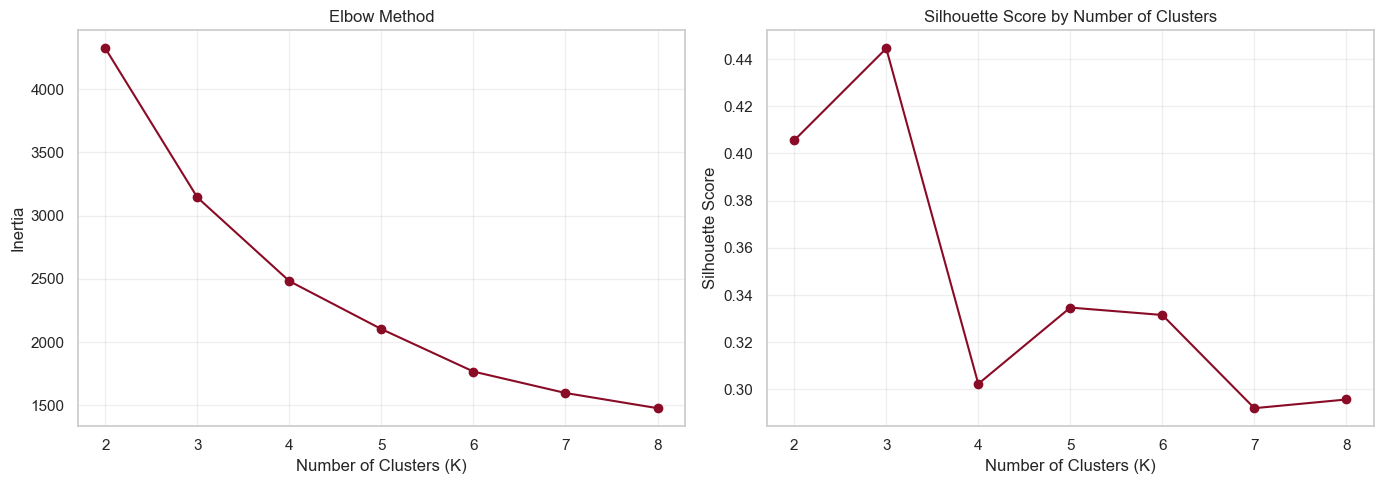

In [88]:
# 1. Select the initial clustering features
cluster_features = [
    "stargazers_count",
    "forks_count",
    "contribs_count",
    "documentation_score"
]

X_cluster = cluster_source[cluster_features].copy()

# 2. Reduce skewness in popularity metrics
X_cluster["stargazers_count"] = np.log1p(
    X_cluster["stargazers_count"]
)

X_cluster["forks_count"] = np.log1p(
    X_cluster["forks_count"]
)

# 3. Standardize all features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Original dataset shape:", X_cluster.shape)
print("Scaled dataset shape:", X_scaled.shape)
print("Missing values:", X_cluster.isna().sum().sum())
print("Infinite values:", np.isfinite(X_scaled).all())

# 4. Evaluate different values of K
k_results = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    k_results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette_Score": silhouette_score(
            X_scaled, labels
        )
    })

k_results_df = pd.DataFrame(k_results)

display(
    k_results_df.style.format({
        "Inertia": "{:,.2f}",
        "Silhouette_Score": "{:.4f}"
    })
)

# 5. Visualize Elbow Method
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    k_results_df["K"],
    k_results_df["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(k_results_df["K"])
axes[0].grid(alpha=0.3)

# 6. Visualize Silhouette Scores
axes[1].plot(
    k_results_df["K"],
    k_results_df["Silhouette_Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score by Number of Clusters")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_results_df["K"])
axes[1].grid(alpha=0.3)

plt.tight_layout()
save_and_show('Elbow_Method_and_Silhouette_Scores')

### Transformation and Scaling Review

Stars and forks have been log-transformed to reduce the influence of extreme popularity values. The selected features have then been standardized to make their scales more comparable.

These transformations help prevent raw numerical magnitudes from dominating the distance calculations used by K-Means.

However, transformations do not resolve inaccurate or incomplete source data. We must still assess whether each feature provides a reliable basis for segmentation.

### Cluster-Number Evaluation

The evaluation results allow us to compare candidate values of \(K\) in terms of cluster compactness and separation.

The Silhouette Score will be used as an important selection criterion, while the Elbow Method will provide additional evidence about the benefit of increasing the number of clusters.

A higher Silhouette Score does not automatically guarantee the most useful business segmentation. We must also inspect the resulting cluster profiles and investigate whether any feature disproportionately drives the separation.

----------------

In [89]:
# 1. Fit the selected K-Means model
best_k = 3

kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

cluster_labels = kmeans_final.fit_predict(X_scaled)

# 2. Attach cluster labels to the repository data
clustered_repos = cluster_source.copy()
clustered_repos["cluster"] = cluster_labels

# 3. Cluster sizes
cluster_sizes = (
    clustered_repos["cluster"]
    .value_counts()
    .sort_index()
    .rename("Repository_Count")
    .to_frame()
)

cluster_sizes["Percentage"] = (
    cluster_sizes["Repository_Count"]
    / len(clustered_repos) * 100
)

display(
    cluster_sizes.style.format({
        "Repository_Count": "{:,.0f}",
        "Percentage": "{:.2f}%"
    })
)

# 4. Profile the clusters using the original feature values
profile_features = [
    "stargazers_count",
    "forks_count",
    "contribs_count",
    "documentation_score"
]

cluster_profile = (
    clustered_repos
    .groupby("cluster")[profile_features]
    .agg(["median", "mean"])
    .round(2)
)

display(cluster_profile)

# 5. Inspect representative repositories
display(
    clustered_repos[
        [
            "repo_name",
            "language",
            "stargazers_count",
            "forks_count",
            "contribs_count",
            "documentation_score",
            "cluster"
        ]
    ]
    .sort_values(
        ["cluster", "stargazers_count"],
        ascending=[True, False]
    )
    .groupby("cluster")
    .head(5)
    .sort_values(["cluster", "stargazers_count"],
                 ascending=[True, False])
    .reset_index(drop=True)
)


,Repository_Count,Percentage
cluster,,
0,"1,161",73.57%
1,347,21.99%
2,70,4.44%


stargazers_count         forks_count        contribs_count         \
                  median    mean      median   mean         median   mean   
cluster                                                                     
0                    5.0    7.34         1.0   1.83            2.0   3.24   
1                   62.0  209.75        16.0  47.87            3.0   4.44   
2                    4.0   16.57         1.0   7.39           30.0  27.73   

        documentation_score        
                     median  mean  
cluster                            
0                       5.0  5.00  
1                       5.0  4.87  
2                       5.0  5.74

,repo_name,language,stargazers_count,forks_count,contribs_count,documentation_score,cluster
0,10Mica,C,68,0,2,6,0
1,Learn-Quran-App,TypeScript,40,2,3,5,0
2,nodearch,TypeScript,39,3,2,7,0
3,arabic-lib-transformers,Python,37,1,2,4,0
4,follows-you-github,JavaScript,36,1,2,4,0
5,Sublist3r,Python,9734,2104,21,5,1
6,DeepLearning.ai-Summary,Python,5151,2444,22,4,1
7,autoComplete.js,JavaScript,3939,237,30,6,1
8,Shell,C++,3372,113,27,6,1
9,Competitive-programming-li...,Java,2445,472,16,5,1


----

## 7. Feature Reliability and Sensitivity Analysis

Before finalizing the clustering model, we will assess the influence of `contribs_count` on the resulting repository segments.

The initial clustering experiment produced a cluster in which a large proportion of repositories had exactly 30 contributors. This concentration raises a potential data collection concern, such as a request limit or another extraction constraint, although the repeated value alone does not prove that a limit was applied.

If a feature has been capped or recorded inconsistently, it may influence the clustering structure in a misleading way.

To investigate this possibility, we will conduct a **sensitivity analysis**:

1. Evaluate the initial model using the candidate features, including contributor counts.
2. Inspect the resulting cluster profiles and the distribution of contributor counts.
3. Fit an alternative model after excluding `contribs_count`.
4. Compare the evaluation metrics and resulting cluster profiles.

This comparison will help us determine whether the contributor feature substantially changes the segmentation.

**Decision principle:** The final model should be based on features that are sufficiently reliable and produce interpretable segments, rather than on the highest evaluation score alone.

In [90]:
# 1. Check cluster sizes
cluster_sizes = (
    clustered_repos["cluster"]
    .value_counts()
    .sort_index()
    .rename("Repository_Count")
    .to_frame()
)

cluster_sizes["Percentage"] = (
    cluster_sizes["Repository_Count"]
    / len(clustered_repos) * 100
)

display(cluster_sizes.round(2))

# 2. Inspect contribs_count distribution
print("contribs_count frequency distribution:")
display(
    clustered_repos["contribs_count"]
    .value_counts()
    .sort_index()
    .to_frame("Repository_Count")
    .tail(15)
)

print(
    "Repositories with contribs_count == 30:",
    (clustered_repos["contribs_count"] == 30).sum()
)

print(
    "Percentage at value 30:",
    round(
        (clustered_repos["contribs_count"] == 30).mean() * 100,
        2
    ),
    "%"
)

# 3. Check whether value 30 dominates Cluster 2
contribs_diagnostic = (
    clustered_repos
    .groupby("cluster")["contribs_count"]
    .agg(
        Repository_Count="size",
        Median="median",
        Mean="mean",
        Count_Equal_30=lambda s: (s == 30).sum(),
        Percentage_Equal_30=lambda s: (s == 30).mean() * 100
    )
    .round(2)
)

display(contribs_diagnostic)

,Repository_Count,Percentage
cluster,,
0,1161,73.57
1,347,21.99
2,70,4.44


contribs_count frequency distribution:


,Repository_Count
contribs_count,
12,7
13,7
14,3
15,6
16,4
17,6
18,2
19,2
20,1


Repositories with contribs_count == 30: 55
Percentage at value 30: 3.49 %


,Repository_Count,Median,Mean,Count_Equal_30,Percentage_Equal_30
cluster,,,,,
0,1161,2.0,3.24,0,0.00
1,347,3.0,4.44,1,0.29
2,70,30.0,27.73,54,77.14


,K,Inertia,Silhouette_Score
0,2,"2,747.74",0.4596
1,3,"2,025.56",0.3435
2,4,"1,638.01",0.3681
3,5,"1,304.15",0.3597
4,6,"1,136.26",0.3203
5,7,"1,009.93",0.3287
6,8,922.79,0.3184


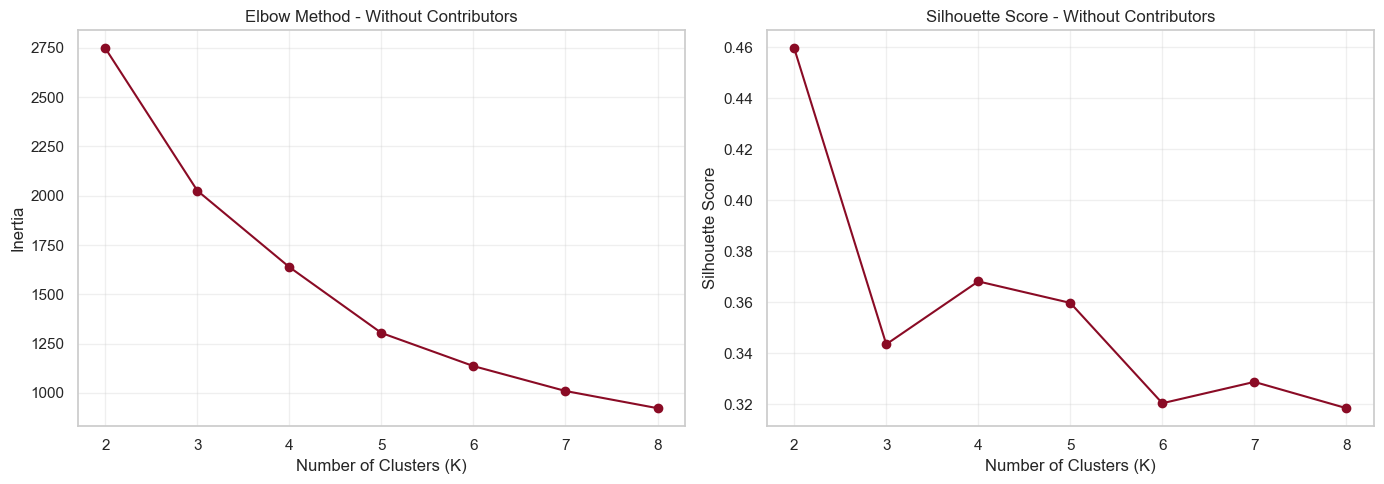

,Original_Cluster_Count,Without_Contribs_Count
0,1161,824
1,347,424
2,70,330


In [91]:
# 1. Build alternative features without contribs_count
sensitivity_features = [
    "stargazers_count",
    "forks_count",
    "documentation_score"
]

X_sensitivity = cluster_source[sensitivity_features].copy()

# Reduce skewness in popularity metrics
X_sensitivity["stargazers_count"] = np.log1p(
    X_sensitivity["stargazers_count"]
)

X_sensitivity["forks_count"] = np.log1p(
    X_sensitivity["forks_count"]
)

# Standardize the alternative feature set
scaler_sensitivity = StandardScaler()
X_sensitivity_scaled = scaler_sensitivity.fit_transform(
    X_sensitivity
)

# 2. Compare K values from 2 to 8
sensitivity_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_sensitivity_scaled)

    sensitivity_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette_score(
            X_sensitivity_scaled,
            labels
        )
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(
    sensitivity_df.style.format({
        "Inertia": "{:,.2f}",
        "Silhouette_Score": "{:.4f}"
    })
)

# 3. Visualize the alternative model evaluation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    sensitivity_df["K"],
    sensitivity_df["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method - Without Contributors")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(sensitivity_df["K"])
axes[0].grid(alpha=0.3)

axes[1].plot(
    sensitivity_df["K"],
    sensitivity_df["Silhouette_Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score - Without Contributors")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(sensitivity_df["K"])
axes[1].grid(alpha=0.3)

plt.tight_layout()
save_and_show('Sensitivity_Analysis')

# 4. Fit the alternative model using K=3 for direct comparison
kmeans_sensitivity = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

clustered_repos_sensitivity = cluster_source.copy()
clustered_repos_sensitivity["cluster_without_contribs"] = (
    kmeans_sensitivity.fit_predict(X_sensitivity_scaled)
)

# Compare cluster sizes
comparison_sizes = pd.concat(
    [
        clustered_repos["cluster"]
        .value_counts()
        .sort_index()
        .rename("Original_Cluster_Count"),

        clustered_repos_sensitivity["cluster_without_contribs"]
        .value_counts()
        .sort_index()
        .rename("Without_Contribs_Count")
    ],
    axis=1
).fillna(0).astype(int)

display(comparison_sizes)


---

## 8. Final K-Means Model

Based on the sensitivity analysis, we will fit the final K-Means model using two clusters and the selected features:

- Log-transformed stars
- Log-transformed forks
- Documentation score

Contributor counts are excluded from the clustering inputs because of the potential data collection concern identified in the initial experiment.

The fitted cluster labels will be added to a separate copy of the repository dataset. This preserves the original data and allows us to examine the characteristics of each segment.

The cluster labels are arbitrary identifiers, not rankings. We will assign descriptive names only after inspecting the cluster profiles.

In [92]:
# 1. Fit the alternative model using K=2
kmeans_final_sensitivity = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

clustered_repos_sensitivity = cluster_source.copy()

clustered_repos_sensitivity["cluster"] = (
    kmeans_final_sensitivity.fit_predict(
        X_sensitivity_scaled
    )
)

# 2. Cluster sizes
cluster_sizes_final = (
    clustered_repos_sensitivity["cluster"]
    .value_counts()
    .sort_index()
    .rename("Repository_Count")
    .to_frame()
)

cluster_sizes_final["Percentage"] = (
    cluster_sizes_final["Repository_Count"]
    / len(clustered_repos_sensitivity) * 100
)

display(
    cluster_sizes_final.style.format({
        "Repository_Count": "{:,.0f}",
        "Percentage": "{:.2f}%"
    })
)

# 3. Profile clusters using original values
profile_features_final = [
    "stargazers_count",
    "forks_count",
    "contribs_count",
    "documentation_score"
]

cluster_profile_final = (
    clustered_repos_sensitivity
    .groupby("cluster")[profile_features_final]
    .agg(["median", "mean"])
    .round(2)
)

display(cluster_profile_final)

# 4. Inspect the most popular repositories in each cluster
representative_repos = (
    clustered_repos_sensitivity[
        [
            "repo_name",
            "language",
            "stargazers_count",
            "forks_count",
            "contribs_count",
            "documentation_score",
            "cluster"
        ]
    ]
    .sort_values(
        ["cluster", "stargazers_count"],
        ascending=[True, False]
    )
    .groupby("cluster")
    .head(10)
    .reset_index(drop=True)
)

display(representative_repos)

# 5. Verify the final model's Silhouette Score
print(
    "Final Silhouette Score (K=2):",
    round(
        silhouette_score(
            X_sensitivity_scaled,
            clustered_repos_sensitivity["cluster"]
        ),
        4
    )
)


,Repository_Count,Percentage
cluster,,
0,"1,218",77.19%
1,360,22.81%


stargazers_count         forks_count        contribs_count        \
                  median    mean      median   mean         median  mean   
cluster                                                                    
0                    5.0    7.18         1.0   1.85            3.0  4.43   
1                   60.5  204.77        16.0  47.22            3.0  5.13   

        documentation_score        
                     median  mean  
cluster                            
0                       5.0  5.04  
1                       5.0  4.88

,repo_name,language,stargazers_count,forks_count,contribs_count,documentation_score,cluster
0,10Mica,C,68,0,2,6,0
1,Learn-Quran-App,TypeScript,40,2,3,5,0
2,nodearch,TypeScript,39,3,2,7,0
3,arabic-lib-transformers,Python,37,1,2,4,0
4,follows-you-github,JavaScript,36,1,2,4,0
5,Data_Engineering_Mentorship,Java,34,1,6,8,0
6,CP-Circus,C++,33,1,2,7,0
7,Book-Scraper,Python,32,1,3,5,0
8,Guava,Python,30,2,2,4,0
9,Memcury,C++,29,4,5,6,0


Final Silhouette Score (K=2): 0.4596


### Sensitivity Analysis Findings

The initial model produced a cluster containing 70 repositories, of which 54 had exactly 30 contributors. This concentration suggests that the contributor variable may be influencing the clustering structure and warrants further investigation.

After excluding `contribs_count`, the alternative model with \(K=2\) achieved a Silhouette Score of approximately **0.4596**.

The resulting segments are primarily differentiated by repository popularity, measured through stars and forks.

This alternative model is preferable for the current analysis because it avoids relying on a potentially problematic contributor feature. Nevertheless, the repeated contributor value should be described as a **potential collection limitation**, not a confirmed API cap, unless independently verified.

The two-cluster solution will therefore be used for the next stage of profiling and visualization.

### Initial Cluster Profiles

The two-cluster solution separates the repositories into groups with different popularity profiles.

- **Cluster 0:** 1,218 repositories (77.19%), with a median of 5 stars and 1 fork.
- **Cluster 1:** 360 repositories (22.81%), with a median of 60.5 stars and 16 forks.

Both clusters have a median contributor count of 3 and a median documentation score of 5. These variables do not show a difference in their medians between the two groups in this profile.

The main observed distinction is therefore repository popularity, particularly stars and forks.

The means are higher than the medians for popularity measures, suggesting that a relatively small number of highly popular repositories influence the averages.

These are descriptive findings. We will use visualizations to examine the distributions and assess how clearly the two groups differ.

----

## 9. Cluster Visualization and Interpretation

To examine the separation between the two repository segments, we will visualize the distributions of stars and forks after applying the `log1p` transformation.

The visualizations will help us investigate:

- Whether the two clusters show different popularity distributions.
- Whether their distributions overlap substantially or exhibit a noticeable shift.
- Whether a small number of highly popular repositories affect the overall pattern.

Histograms will be used to compare the transformed stars and forks distributions across clusters. We will interpret them alongside the numerical cluster profiles rather than treating visual separation as proof that the clusters are objectively distinct.

**Important:** The plotted values are log-transformed counts, not raw stars or forks. The visualizations describe the clusters created by the model; they do not establish that cluster membership causes repository popularity.

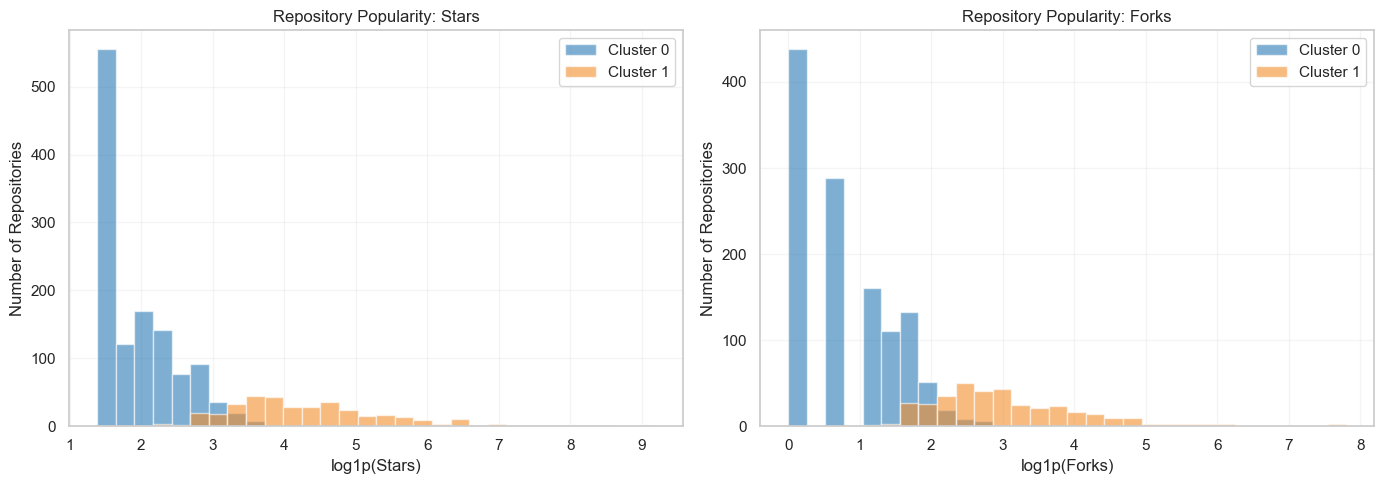

In [93]:
import matplotlib.pyplot as plt
import numpy as np

plot_data = clustered_repos_sensitivity.copy()

plot_data["log_stars"] = np.log1p(plot_data["stargazers_count"])
plot_data["log_forks"] = np.log1p(plot_data["forks_count"])

# Distinct colors for better visual comparison
cluster_colors = {
    0: "#2878B5",  # Blue
    1: "#F28E2B"   # Orange
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Use shared bin edges so both clusters are compared on the same scale
stars_bins = np.histogram_bin_edges(plot_data["log_stars"], bins=30)
forks_bins = np.histogram_bin_edges(plot_data["log_forks"], bins=30)

for cluster_id in sorted(plot_data["cluster"].unique()):
    subset = plot_data.loc[plot_data["cluster"] == cluster_id]
    color = cluster_colors[cluster_id]

    axes[0].hist(
        subset["log_stars"],
        bins=stars_bins,
        alpha=0.60,
        color=color,
        label=f"Cluster {cluster_id}"
    )

    axes[1].hist(
        subset["log_forks"],
        bins=forks_bins,
        alpha=0.60,
        color=color,
        label=f"Cluster {cluster_id}"
    )

axes[0].set_title("Repository Popularity: Stars")
axes[0].set_xlabel("log1p(Stars)")
axes[0].set_ylabel("Number of Repositories")
axes[0].legend()

axes[1].set_title("Repository Popularity: Forks")
axes[1].set_xlabel("log1p(Forks)")
axes[1].set_ylabel("Number of Repositories")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.20)

plt.tight_layout()
save_and_show('Cluster_Distribution')

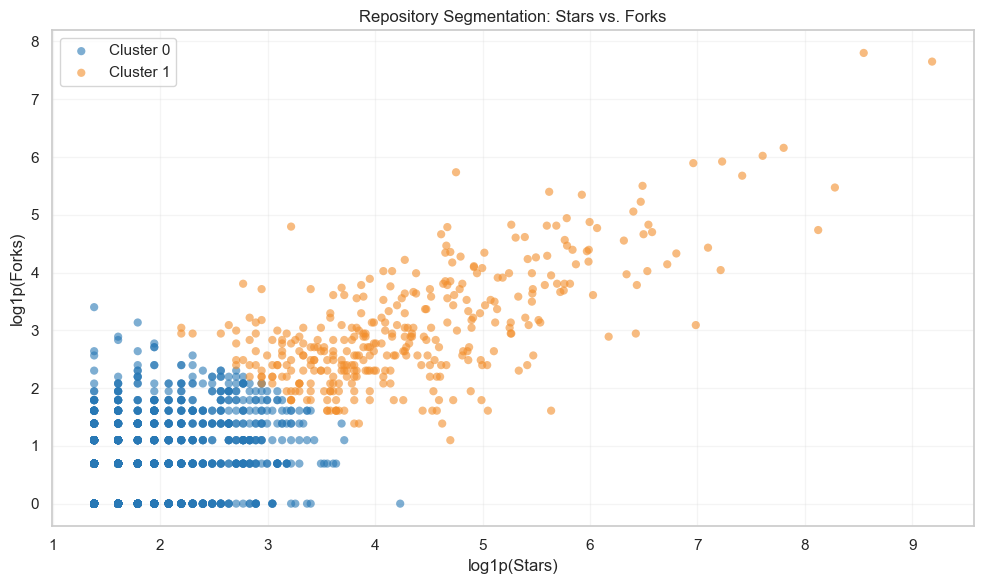

In [94]:
import matplotlib.pyplot as plt
import numpy as np

plot_data = clustered_repos_sensitivity.copy()

plot_data["log_stars"] = np.log1p(plot_data["stargazers_count"])
plot_data["log_forks"] = np.log1p(plot_data["forks_count"])

cluster_colors = {
    0: "#2878B5",
    1: "#F28E2B"
}

plt.figure(figsize=(10, 6))

for cluster_id in sorted(plot_data["cluster"].unique()):
    subset = plot_data.loc[plot_data["cluster"] == cluster_id]

    plt.scatter(
        subset["log_stars"],
        subset["log_forks"],
        color=cluster_colors[cluster_id],
        label=f"Cluster {cluster_id}",
        alpha=0.60,
        s=35,
        edgecolors="none"
    )

plt.title("Repository Segmentation: Stars vs. Forks")
plt.xlabel("log1p(Stars)")
plt.ylabel("log1p(Forks)")
plt.legend()
plt.grid(alpha=0.20)
plt.tight_layout()
save_and_show('Clusters_Forks_vs_Stars')

### Visualization Findings: Comparing Repository Popularity Across Clusters

The histograms illustrate the distributions of log-transformed stars and forks for the two repository clusters.

**1. Stars Distribution**

Cluster 0 is concentrated at relatively low star counts, with a median of 5 stars. Cluster 1 is shifted toward higher values, with a median of 60.5 stars.

Although the distributions overlap, Cluster 1 generally contains more popular repositories in terms of GitHub stars.

**2. Forks Distribution**

A similar pattern appears in the forks distribution. Cluster 0 has a median of 1 fork, whereas Cluster 1 has a median of 16 forks.

This indicates that Cluster 1 generally contains repositories with greater forking activity.

**3. Documentation Score**

Both clusters have a median documentation score of 5. Therefore, the current cluster profiles do not indicate a difference in median documentation score between the two groups.

**4. Overall Interpretation**

The visualizations support interpreting the two clusters as repository segments with different popularity profiles:

- **Cluster 0 — Lower-Popularity Repositories:** 1,218 repositories (77.19%), characterized by lower median star and fork counts.
- **Cluster 1 — Higher-Popularity Repositories:** 360 repositories (22.81%), characterized by higher median star and fork counts.

The distributions are not completely separated, so cluster membership should not be interpreted as a strict popularity ranking for every individual repository.

These findings are descriptive and do not establish causation. In addition, the histograms use `log1p`-transformed values, so their horizontal axes represent transformed counts rather than raw stars or forks.

----

<div style="padding:10px;
            color:#E55604;
            margin:10px;
            font-size:180%;
            display:fill;
            border-radius:5px;
            border-style: solid;
            border-color: #FF9B50;
            background-color:#000000;
            overflow:hidden;
            font-weight:800;
            text-align:
            center;"><b>Final Insights and Recommendations</b>

## 1. Key Findings

This project analyzed Egyptian open-source repositories to explore their characteristics, popularity indicators, and contribution patterns. The analysis combined exploratory data analysis, statistical hypothesis testing, and repository segmentation.

### 1.1 Repository Popularity

A strong positive monotonic association was observed between GitHub stars and forks (Spearman's \(\rho = 0.664\), \(p < 0.001\)).

Repositories with more stars generally tended to have more forks. However, this association does not establish that increasing stars causes more forks, or vice versa.

### 1.2 Contributor Counts and Popularity

The relationship between contributor counts and stars was not statistically significant (\(\rho = 0.004\), \(p = 0.876\)).

A weak positive association was observed between contributor counts and forks (\(\rho = 0.122\), adjusted \(p < 0.001\)).

These findings suggest that contributor counts alone do not explain repository popularity in this dataset. The weak association with forks should not be interpreted as evidence of a strong relationship.

### 1.3 Documentation Indicators and Popularity

The documentation score had a weak negative association with stars (\(\rho = -0.146\), adjusted \(p < 0.001\)). No statistically significant association was found between the documentation score and forks (\(\rho = -0.025\), \(p = 0.325\)).

The negative association does not mean that documentation reduces popularity. The score is a heuristic measure of selected documentation indicators, not a comprehensive assessment of documentation quality. Other factors may help explain the observed relationship.

### 1.4 Programming Language Differences

Kruskal–Wallis tests indicated statistically significant differences in the distributions of stars and forks across the programming language groups examined (stars: \(p = 0.00395\); forks: \(p = 0.0000695\)).

Post-hoc comparisons with Holm correction identified some significant pairwise differences. For example, PHP repositories had higher median stars than Dart and C repositories in the comparisons that reached statistical significance. PHP also had higher median forks than Dart, JavaScript, TypeScript, and C++ in the significant comparisons.

These results indicate that popularity distributions vary across some language groups. They do not establish that a programming language itself causes greater popularity, and they do not imply that every pair of languages differs significantly.

### 1.5 Repository Segmentation

The final K-Means model identified two repository segments using stars, forks, and the documentation score, after excluding contributor counts because of a potential data collection limitation.

- **Cluster 0 — Lower-Popularity Repositories:** 1,218 repositories (77.19%), with median values of 5 stars and 1 fork.
- **Cluster 1 — Higher-Popularity Repositories:** 360 repositories (22.81%), with median values of 60.5 stars and 16 forks.

Both clusters had a median documentation score of 5. The clearest observed distinction between the groups was therefore their popularity indicators.

The alternative two-cluster model achieved a Silhouette Score of approximately 0.4596. This provides a useful measure of cluster separation, but it does not prove that the segmentation is definitive or that the clusters represent repository quality.

## 2. Overall Conclusion

The analysis shows that repository popularity, contributor counts, documentation indicators, and programming language do not exhibit the same patterns across the dataset.

Stars and forks were positively associated, while contributor counts showed no meaningful association with stars and only a weak positive association with forks. Documentation scores were not positively associated with popularity in the analyses performed. Popularity distributions also differed across some programming language groups.

The clustering analysis provided a complementary view by separating repositories into lower- and higher-popularity segments. These groups were primarily distinguished by their stars and forks rather than by their median documentation scores.

Overall, the findings describe patterns within the collected dataset of Egyptian open-source repositories. They should not automatically be generalized to all Egyptian developers or all open-source projects.

## 3. Recommendations

Based on the observed findings, the following recommendations may be useful for repository maintainers and the Egyptian open-source community.

### 3.1 Improve Project Discoverability

Repository maintainers may benefit from clear project descriptions, relevant topics, useful README files, and straightforward setup instructions. These practices can help potential users understand and discover projects, although their impact on popularity was not established by this analysis.

### 3.2 Encourage Meaningful Community Participation

Because contributor counts alone did not show a significant association with stars, community growth should not be evaluated using contributor counts alone. Maintainers can also consider the quality of contributions, issue resolution, community discussions, and the sustainability of project maintenance.

### 3.3 Strengthen Documentation Practices

The documentation score used in this project measures the presence of selected documentation indicators rather than actual quality or usefulness. Maintainers should focus on documentation that helps users install, understand, use, and contribute to their projects instead of simply maximizing a checklist score.

### 3.4 Interpret Language-Based Comparisons Carefully

The observed differences between some programming language groups may be useful for further investigation. However, language selection should not be based on popularity comparisons alone. Project purpose, repository age, ecosystem size, and other factors may also influence popularity.

### 3.5 Monitor Repository Activity and Data Quality

Future analyses would benefit from more complete and consistently collected activity data, including reliable commit histories and verified contributor counts. Better data quality would support more confident comparisons of repository activity and community participation.

## 4. Limitations

Several limitations should be considered when interpreting the findings:

- **Data completeness:** Some variables, including last commit dates and repository topics, had substantial missing values.
- **Potential collection limits:** The repeated contributor count of 30 may reflect a data collection limitation, but this was not independently confirmed.
- **Heuristic documentation score:** The score measures predefined indicators and should not be treated as a direct measure of documentation quality.
- **Observational analysis:** Statistical associations do not establish causality.
- **Uneven group sizes:** Programming language groups and repository clusters differ in size, which should be considered when comparing results.
- **Clustering interpretation:** K-Means segments depend on the selected features, transformations, scaling, and number of clusters.
- **Scope of the dataset:** Findings apply to the repositories represented in the collected dataset and may not represent the entire Egyptian open-source ecosystem.

## 5. Final Statement

This project provides an initial analytical overview of Egyptian open-source repositories by examining popularity, contribution patterns, documentation indicators, programming language differences, and repository segments.

The results offer a foundation for understanding patterns in the collected data while highlighting the importance of data quality, careful statistical interpretation, and transparent reporting of limitations.